# Selection on structural variants — Figure 2: GrENE-Net, is the selection still acting?

Condensed from `sv_selection_key_results.ipynb` (full per-context panels, tables and robustness there); Figures 1–3 are built separately (`_build_main_fig{1,2,3}_nb.py`), shared code in `_main_fig_common.py`.

**Unit and filters** (as in the key-results notebook): the SV **event** (arch3 alleles of a pangenome
bubble merged with `truvari collapse` defaults); called in ≥ 90% of the 231 founders throughout;
≥ 2 carrier founders for the GrENE-Net analyses and the composition panels, singletons included in the
spectra (Figure 1a–b, 3a). Context, first match wins: CDS > UTR > intron > reference TE > promoter
(≤ 2 kb upstream) > intergenic. Colours: insertions orange, deletions green, SNPs black, short indels grey.

In [1]:

import os
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from scipy import stats
import statsmodels.api as sm
from matplotlib.ticker import PercentFormatter
plt.rcParams.update({'figure.dpi':120,'font.size':8,'axes.linewidth':0.6,'savefig.bbox':'tight'})
G=os.path.abspath(os.path.join(os.getcwd(),"..","r1_sv_negative_selection","results","sv_adaptive"))
CTX=["CDS","UTR","intron","TE","promoter","intergenic"]
KC={"snp":"0.15","indel":"0.62","ins":"#D95F02","del":"#1B9E77"}; KL={"snp":"SNPs","indel":"short indels","ins":"insertions","del":"deletions"}
OC={"cold-specific":"#2166AC","shared":"0.45","warm-specific":"#B2182B"}
def style(ax,axis="both"):
    ax.set_axisbelow(True); ax.grid(color="0.9",lw=0.6,axis=axis)
    for sp in ax.spines.values(): sp.set_visible(False)
def panel(ax,letter): ax.annotate(letter,xy=(-0.12,1.04),xycoords="axes fraction",fontsize=11,fontweight="bold")
rng=np.random.default_rng(0)
D=pd.read_csv(f"{G}/sv_event_catalog.csv"); PALL=np.load(f"{G}/sv_event_catalog_p_poolaf.npy")   # kMate pool allele frequencies (seed mix + each garden)
ok=D.passes.to_numpy(); E=D[ok].reset_index(drop=True); PE=PALL[ok]
CS=np.load(f"{G}/classic_sfs.npz"); M=int(CS["M"])
def maf(name): c=CS[f"{name}_c"].astype(float); k=CS[f"{name}_k"].astype(float); f=c/k; return np.minimum(f,1-f)
def tajD(names):
    # Tajima's D of a class, directly from its variants (no projection): per variant, c carriers among k called founders
    names=[names] if isinstance(names,str) else names
    c=np.concatenate([CS[f"{n}_c"] for n in names]).astype(float); k=np.concatenate([CS[f"{n}_k"] for n in names]).astype(float)
    h=2*c*(k-c)/(k*(k-1)); n=int(np.median(k)); j=np.arange(1,n); a1=(1/j).sum(); a2=(1/j**2).sum()
    b1=(n+1)/(3*(n-1)); b2=2*(n*n+n+3)/(9*n*(n-1)); c1=b1-1/a1; c2=b2-(n+2)/(a1*n)+a2/a1**2; e1=c1/a1; e2=c2/(a1**2+a2)
    D=lambda hh:(hh.sum()-hh.size/a1)/np.sqrt(e1*hh.size+e2*hh.size*(hh.size-1))
    return D(h),h,D
def tajD_matched(snp_name,sv_name,per=50,seed=0):
    # Tajima's D of SNPs re-weighted to the SV class's call-rate distribution: for every value of k (called founders) among the
    # SV events, draw up to per x (number of events with that k) SNPs with exactly that k. Bootstrap CI over the drawn SNPs.
    r=np.random.default_rng(seed); cs=CS[f"{snp_name}_c"].astype(int); ks=CS[f"{snp_name}_k"].astype(int); kv=CS[f"{sv_name}_k"].astype(int)
    pick=[]
    for kk,n in zip(*np.unique(kv,return_counts=True)):
        pool=np.where(ks==kk)[0]
        if pool.size: pick.append(r.choice(pool,min(per*n,pool.size),replace=False))
    pick=np.concatenate(pick); c=cs[pick].astype(float); k=ks[pick].astype(float)
    h=2*c*(k-c)/(k*(k-1)); n=int(np.median(k)); j=np.arange(1,n); a1=(1/j).sum(); a2=(1/j**2).sum()
    b1=(n+1)/(3*(n-1)); b2=2*(n*n+n+3)/(9*n*(n-1)); c1=b1-1/a1; c2=b2-(n+2)/(a1*n)+a2/a1**2; e1=c1/a1; e2=c2/(a1**2+a2)
    D=lambda hh:(hh.sum()-hh.size/a1)/np.sqrt(e1*hh.size+e2*hh.size*(hh.size-1)); bs=[D(r.choice(h,h.size)) for _ in range(100)]
    return D(h),np.percentile(bs,2.5),np.percentile(bs,97.5)
def tajD_ci(names,B=300):
    d,h,D=tajD(names)
    if h.size>20000:                                  # large SNP classes: CI is negligible, fewer draws
        bs=[D(rng.choice(h,h.size)) for _ in range(40)]
    else: bs=[D(rng.choice(h,h.size)) for _ in range(B)]
    return d,np.percentile(bs,2.5),np.percentile(bs,97.5)
print(f"events passing: {len(E):,} ({(E.kind=='ins').sum():,} insertions, {(E.kind=='del').sum():,} deletions)")
# robustness checks (`_sv_main_figures_checks.py`): matched-SNP-set null for the load statistic, founder
# origin in the burden model, spectra without singletons
CKM=pd.read_csv(f"{G}/main_fig_checks_lmm.csv").set_index("check")
CKS=pd.read_csv(f"{G}/main_fig_checks_nosingleton.csv")
pfmt=lambda p: "p < 0.001" if p<=0.001 else f"p = {p:.2g}"


events passing: 18,418 (12,981 insertions, 5,437 deletions)


In [2]:

GS=np.load(f"{G}/garden_af_event.npz"); PV=GS["p"].astype(np.float64); KD=GS["kind"].astype(str); CX=GS["ctx"]; ZN=GS["zone"].astype(str); ORG=GS["origin"].astype(str); BIO=GS["bio1"]
NCAR=GS["n"].astype(int); BQ=np.quantile(GS["b1"][KD=="snp"],[0.2,0.4,0.6,0.8]); QCL=np.digitize(GS["b1"],BQ)          # carrier-climate quintile (edges from SNPs)
CB=np.array([2,3,4,5,6,8,11,16,26,51,1000])
CELLX=NCAR*10+QCL                                   # exact match: same number of carrier founders x same carrier-climate quintile
CELLB=np.digitize(NCAR,CB)*10+QCL                   # fallback: carrier-count bin x quintile, used only when the exact cell holds no SNP
SH=(GS["nc"]>0)&(GS["nw"]>0); zc=np.where(ZN=="cold","#2166AC",np.where(ZN=="hot","#B2182B","0.6"))
CATZ=np.full(int(GS["cat_row"].max())+1,-1); CATZ[GS["cat_row"][GS["cat_row"]>=0]]=np.where(GS["cat_row"]>=0)[0]   # catalog row -> row here
def matched_snps(ms,mn,cx=None,cb=None):
    # every event is compared with ALL SNPs of the comparison set in its cell (default: carrier count x climate quintile, CELLX;
    # fallback CELLB when the exact cell holds no SNP); the SNP set is weighted so its composition equals the events'
    cx=CELLX if cx is None else cx; cb=CELLB if cb is None else cb
    si=np.where(mn)[0]; w=np.zeros(si.size); ex=cx[si]; cbs=cb[si]
    cnt_ex=pd.Series(ex).value_counts(); cnt_cb=pd.Series(cbs).value_counts(); nfall=0
    for c,k in pd.Series(cx[ms]).value_counts().items():
        if c in cnt_ex.index: w[ex==c]+=k/cnt_ex[c]
        else:
            b=cb[ms][cx[ms]==c][0]; nfall+=k
            if b in cnt_cb.index: w[cbs==b]+=k/cnt_cb[b]
    return si,w,nfall
def load_diff(ms,mn,cx=None,cb=None):
    # per garden: relative change of the class's summed frequency (its load) minus the same for the matched SNPs
    si,w,_=matched_snps(ms,mn,cx,cb); Ls=np.nansum(PV[ms],0); Ln=np.nansum(PV[si]*w[:,None],0)
    return (Ls[1:]/Ls[0]-1)-(Ln[1:]/Ln[0]-1)
def rel_change(ms):
    # per garden: relative change of the class's summed frequency from the seed mix, no matching
    Ls=np.nansum(PV[ms],0); return Ls[1:]/Ls[0]-1
CELLF=NCAR*10; CELLFB=np.digitize(NCAR,CB)*10            # frequency-only matching: carrier count, no climate
def _matched_null_compute(ms,mn,ndraw,seed):
    # random SNP sets with the class's composition: one SNP per event drawn from the event's exact cell (fallback: its bin cell), same statistic
    r=np.random.default_rng(seed); si,w,_=matched_snps(ms,mn); Ln=np.nansum(PV[si]*w[:,None],0); base=Ln[1:]/Ln[0]-1
    ex=CELLX[si]; cb=CELLB[si]; pools=[]
    for c,k in pd.Series(CELLX[ms]).value_counts().items():
        pool=si[ex==c]
        if pool.size==0: pool=si[cb==CELLB[ms][CELLX[ms]==c][0]]
        if pool.size: pools.append((pool,int(k)))
    out=np.empty(ndraw)
    for t in range(ndraw):
        pick=np.concatenate([r.choice(pool,k) for pool,k in pools]); Ls=np.nansum(PV[pick],0); out[t]=(Ls[1:]/Ls[0]-1-base).mean()
    return out
def null_p(obs,null,two_sided=False):
    return (np.abs(null-null.mean())>=abs(obs-null.mean())).mean() if two_sided else (null<=obs).mean()
import hashlib
def matched_null(ms,mn,ndraw=1000,seed=1):
    key=hashlib.md5(np.packbits(np.asarray(ms)).tobytes()+np.packbits(np.asarray(mn)).tobytes()+f"exact_{ndraw}_{seed}_{PV.shape}_{os.path.getmtime(f'{G}/garden_af_event.npz')}".encode()).hexdigest()[:16]
    os.makedirs(f"{G}/cache",exist_ok=True); f=f"{G}/cache/null_{key}.npy"
    if os.path.exists(f): return np.load(f)
    out=_matched_null_compute(ms,mn,ndraw,seed); np.save(f,out); return out


## Lead analysis — insertions and deletions vs matched same-context SNPs, all gardens

One comparison, six ways. In every figure: all insertions (left) and all deletions (right) in coding
sequence, introns and intergenic sequence; each SV event is compared with **all SNPs of the same
context carried by the same number of founders and by founders of the same origin-climate quintile**
(`matched_snps`), weighted so the SNP set has the events' composition. One dot per garden (31),
coloured by garden temperature; black = mean over gardens ± 95% percentile bootstrap CI (2,000
resamples of gardens). The printed tables add the two-sided empirical p from 1,000 random matched SNP
sets (`matched_snp_null_p`) — gardens share one founder pool, so that is the stricter test.

**Is coding sequence different from the non-coding contexts?** The brackets at the right of each panel
compare the CDS row with the intron row (inner bracket) and with the intergenic row (outer bracket),
within insertions and within deletions: **paired Wilcoxon signed-rank test** on the 31 garden values
(both rows are measured in the same gardens), two-sided; black and bold = p < 0.05, grey = not
significant. The printed tables add the mean paired difference (CDS − other context) with its bootstrap
CI over gardens and the matched-SNP null p of the difference (random matched SNP sets drawn
independently in the two contexts). The Wilcoxon test takes the gardens as independent draws; they
share one founder pool, so where it and the matched-SNP null disagree the null is the conservative one.
No correction for the number of contrasts (2 per SV type per figure).

| | statistic | variants |
|---|---|---|
| **1a** | frequency change | all (≥ 2 carrier founders) |
| **1b** | frequency change | MAF ≥ 5% in the founders (12–219 carriers), events and SNPs |
| **1c** | frequency change, precision-weighted | all (top) and MAF ≥ 5% (bottom) |
| **2a** | selection coefficient | all |
| **2b** | selection coefficient | MAF ≥ 5% |
| **2c** | selection coefficient, precision-weighted | all (top) and MAF ≥ 5% (bottom) |

**Frequency change:** relative change of the class's summed allele frequency from the seed mix to the
garden (each plot at its last sampled generation), minus the same for the matched SNPs (% of start).
**Selection coefficient:** per variant and garden, the slope of logit allele frequency across
generations — for each generation the garden's frequency is the mean over its plots, then an ordinary
least-squares line through t = 0 (seed mix) and generations 1–3, frequencies clipped to
[0.001, 0.999] (`_sv_garden_af.py`, `GARDEN_STAT=gslope`). For a selfing population this is the
per-generation selection coefficient (*s* = −0.01: odds fall ~1% per generation). Δ*s* = mean *s* of
the class minus mean *s* of its matched SNPs. Plots are averaged **before** the logit: plot-level
frequencies are noisy and often exactly zero, and their logits would dominate.
**Weighted (2c):** variants averaged with weight *p*<sub>0</sub>(1 − *p*<sub>0</sub>) (*p*<sub>0</sub> =
seed-mix frequency), the inverse of the sampling variance of a logit frequency, for the SV class and
for the matched SNPs alike; 2a and 2b count every variant once.
**Weighted frequency change (1c):** the frequency-scale twin of 2c. Per variant, the change standardised
by its binomial variance, Δ*p* / [*p*<sub>0</sub>(1 − *p*<sub>0</sub>)] (the first-order estimate of the
total change in log-odds, ≈ *s* × generations), averaged with the same precision weight
*p*<sub>0</sub>(1 − *p*<sub>0</sub>): Σ Δ*p* / Σ *p*<sub>0</sub>(1 − *p*<sub>0</sub>), for the class minus the
same for its matched SNPs. Note what this makes of 1a/1b: their statistic, Σ Δ*p* / Σ *p*<sub>0</sub>, is
**already weighted** — a class's summed frequency counts each variant in proportion to *p*<sub>0</sub>, so
common variants carry it. 1c has the same numerator and only swaps the denominator, so it follows
1a/1b garden by garden (same sign, same gardens below 0; the cell prints the correlation) on a larger
scale, because Σ *p*<sub>0</sub>(1 − *p*<sub>0</sub>) < Σ *p*<sub>0</sub>. The version that counts every
variant once on this scale is, to first order, 2a.

In [3]:

from matplotlib.lines import Line2D
def bci(v,B=2000,seed=2):
    # percentile bootstrap CI of the mean over gardens (resample gardens with replacement)
    r=np.random.default_rng(seed); bs=r.choice(v,(B,v.size)).mean(1); return np.percentile(bs,2.5),np.percentile(bs,97.5)
SUMC=["CDS","intron","intergenic"]
GSs=np.load(f"{G}/garden_sgslope_event.npz"); assert np.array_equal(GSs["kind"].astype(str),KD) and np.array_equal(GSs["n"],GS["n"]) and np.array_equal(GSs["cat_row"],GS["cat_row"])
SS=GSs["p"][:,1:].astype(np.float64)                          # selection coefficient (garden-level slope across generations), variants x 31 gardens
P0=PV[:,0]; W0=P0*(1-P0); ONE=np.ones(P0.size)               # seed-mix frequency; precision weight of a logit frequency
MAC=12; COMMON=(NCAR>=MAC)&(NCAR<=231-MAC); ALLV=np.ones(P0.size,bool)      # MAF >= 5% among 231 founders
def _pools(ms,si):
    ex=CELLX[si]; cb=CELLB[si]; pools=[]
    for c,k in pd.Series(CELLX[ms]).value_counts().items():
        pool=si[ex==c]
        if pool.size==0: pool=si[cb==CELLB[ms][CELLX[ms]==c][0]]
        if pool.size: pools.append((pool,int(k)))
    return pools
def _wm(idx,w): ok=~np.isnan(SS[idx]); return np.nansum(SS[idx]*w[:,None],0)/(w[:,None]*ok).sum(0)
def stat_freq(ms,mn):
    d=load_diff(ms,mn); nl=matched_null(ms,mn); return d,null_p(d.mean(),nl,two_sided=True),nl
def make_stat_s(W):
    def f(ms,mn,ndraw=1000,seed=1):
        si,w,_=matched_snps(ms,mn); im=np.where(ms)[0]; sn=_wm(si,w*W[si]); d=_wm(im,W[im])-sn
        r=np.random.default_rng(seed); pools=_pools(ms,si); nl=np.empty(ndraw)
        for t_ in range(ndraw):
            pick=np.concatenate([r.choice(pool,k) for pool,k in pools]); nl[t_]=(_wm(pick,W[pick])-sn).mean()
        return d,null_p(d.mean(),nl,two_sided=True),nl
    return f
stat_s=make_stat_s(ONE); stat_sw=make_stat_s(W0)
def _wf(idx,w):
    # precision-weighted frequency change of a variant set per garden: sum(w dp) / sum(w p0(1-p0)) = weighted mean of dp/[p0(1-p0)] with weight w p0(1-p0)
    dP=PV[idx,1:]-PV[idx,:1]; ok=~np.isnan(dP); return np.nansum(dP*w[:,None],0)/((W0[idx]*w)[:,None]*ok).sum(0)
def stat_freqw(ms,mn,ndraw=1000,seed=1):
    si,w,_=matched_snps(ms,mn); im=np.where(ms)[0]; sn=_wf(si,w); d=_wf(im,np.ones(im.size))-sn
    r=np.random.default_rng(seed); pools=_pools(ms,si); nl=np.empty(ndraw)
    for t_ in range(ndraw):
        pick=np.concatenate([r.choice(pool,k) for pool,k in pools]); nl[t_]=(_wf(pick,np.ones(pick.size))-sn).mean()
    return d,null_p(d.mean(),nl,two_sided=True),nl
SUMMARY=[]; CONTRASTS=[]
def contrast(dA,nlA,dB,nlB,seed=3):
    # is context A (coding) different from context B? per garden both are "class minus its own matched SNPs", so A - B is a
    # difference of differences, paired by garden. CI: percentile bootstrap over gardens of the mean paired difference.
    # p: the same matched-SNP null as the single-context test -- random matched SNP sets drawn independently in each context,
    # null difference = null_A - null_B (draws paired at random), two-sided around the null mean.
    df=dA-dB; lo,hi=bci(df); nd=nlA-np.random.default_rng(seed).permutation(nlB)
    return df.mean(),lo,hi,int((df<0).sum()),null_p(df.mean(),nd,two_sided=True),stats.wilcoxon(dA,dB).pvalue   # last: paired Wilcoxon signed-rank over the 31 gardens
def show(T,head=None):
    if head: print(f"{head}:")
    print(T.round(4).to_string(index=False)); print("\ncoding sequence against the two non-coding contexts, within each SV type (difference of the matched differences):")
    print(T.attrs["contrasts"].round(4).to_string(index=False)); print()
def lead_figure(stat,flt,label,xlab,pct,fname,axes=None,tag="",sym="Δs"):
    # the lead figure for one statistic and one variant filter; returns the table
    fig=None
    if axes is None: fig,axes=plt.subplots(1,2,figsize=(13,3.4),sharey=True)
    rows=[]; crow=[]
    for a,k in zip(axes,("ins","del")):
        style(a,axis="x"); a.axvline(0,color="0.35",lw=1,ls="--"); DN={}
        for yi,ctx in enumerate(SUMC):
            ci=CTX.index(ctx); ms=(KD==k)&(CX==ci)&flt; mn=(KD=="snp")&(CX==ci)&flt; d,pe,nl=stat(ms,mn); lo,hi=bci(d); DN[ctx]=(d,nl)
            sc_=a.scatter(d,yi+rng.uniform(-0.18,0.18,d.size),c=BIO,cmap="coolwarm",vmin=BIO.min(),vmax=BIO.max(),s=15,alpha=0.85,linewidth=0.3,edgecolor="0.3",zorder=2)
            a.errorbar(d.mean(),yi,xerr=[[d.mean()-lo],[hi-d.mean()]],fmt="o",ms=7,color="0.25",mec="0.1",mew=0.6,capsize=3,elinewidth=1.4,zorder=3)
            txt=(f"{100*d.mean():+.1f}% [{100*lo:+.1f}, {100*hi:+.1f}]" if pct else f"{sym} = {d.mean():+.4f} [{lo:+.4f}, {hi:+.4f}]")
            a.annotate(f"n = {int(ms.sum()):,};  {txt},  {(d<0).sum()}/31 gardens < 0",xy=(0.01,yi-0.46),xycoords=("axes fraction","data"),ha="left",va="top",fontsize=7,color="0.3")
            rows.append(dict(kind=KL[k],context=ctx,n_events=int(ms.sum()),mean=d.mean(),boot_lo=lo,boot_hi=hi,ci_excludes_0=bool(hi<0 or lo>0),gardens_below=int((d<0).sum()),matched_snp_null_p=pe))
            if yi<2: a.axhline(yi+0.5,color="0.9",lw=0.8)
        x0,x1=a.get_xlim(); a.set_xlim(x0,x1+0.20*(x1-x0)); tr=a.get_yaxis_transform()      # room on the right for the brackets (x in axes fraction, y in data)
        for yi,(ctx,xb) in enumerate(zip(SUMC[1:],(0.885,0.955)),1):            # coding sequence against each non-coding context: significance bracket
            m_,l_,h_,nb_,p_,pw_=contrast(*DN["CDS"],*DN[ctx]); sig=pw_<0.05
            a.plot([xb-0.012,xb,xb,xb-0.012],[0,0,yi,yi],transform=tr,color="0.1" if sig else "0.55",lw=1.0,clip_on=False,zorder=5)
            a.text(xb+0.006,yi/2,"p < 0.001" if pw_<0.001 else f"p = {pw_:.2g}",transform=tr,rotation=270,ha="left",va="center",fontsize=7,
                   color="0.1" if sig else "0.5",fontweight="bold" if sig else "normal")
            crow.append(dict(kind=KL[k],contrast=f"CDS - {ctx}",mean_diff=m_,boot_lo=l_,boot_hi=h_,gardens_below=nb_,wilcoxon_p=pw_,significant=bool(sig),matched_snp_null_p=p_))
        a.set_yticks(range(3)); a.set_yticklabels(SUMC,fontsize=8); a.set_ylim(2.4,-0.75); a.set_xlabel(xlab.format(kind=KL[k]),fontsize=8)
        if pct: a.xaxis.set_major_formatter(PercentFormatter(1.0,decimals=0))
        a.annotate(f"{KL[k]}, {label}",xy=(0.02,1.02),xycoords="axes fraction",fontsize=8.5,color="0.2")
    T=pd.DataFrame(rows); SUMMARY.append(T.assign(figure=tag)); T.attrs["contrasts"]=pd.DataFrame(crow); CONTRASTS.append(T.attrs["contrasts"].assign(figure=tag))
    if fig is not None:
        cb=fig.colorbar(sc_,ax=axes,pad=0.01,fraction=0.025); cb.set_label("garden temperature  bio1 (°C)",fontsize=7.5); cb.ax.tick_params(labelsize=7)
        fig.savefig(f"{G}/plots/{fname}",dpi=200,bbox_inches="tight"); plt.show()
    return T,sc_
XF="frequency change of {kind} minus matched same-context SNPs, per garden (% of start)"
XS="Δs per generation: {kind} minus matched same-context SNPs"
print(f"MAF >= 5% (carriers {MAC}-{231-MAC}): "+", ".join(f"{KL[k]} {int(((KD==k)&COMMON).sum()):,} of {int((KD==k).sum()):,}" for k in ("ins","del","snp")))


MAF >= 5% (carriers 12-219): insertions 4,326 of 12,981, deletions 2,444 of 5,437, SNPs 111,142 of 264,595


### 1a. Frequency change — all variants

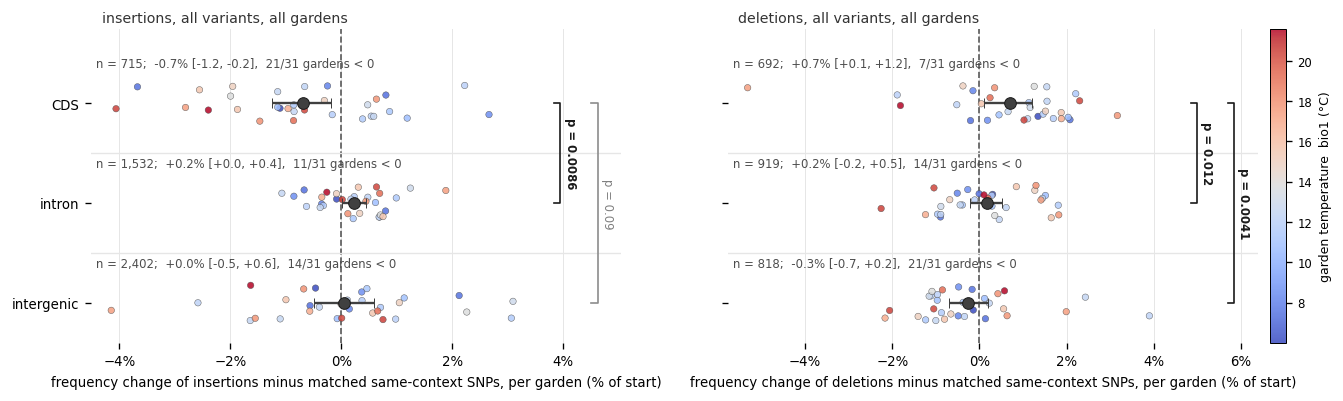

      kind    context  n_events    mean  boot_lo  boot_hi  ci_excludes_0  gardens_below  matched_snp_null_p
insertions        CDS       715 -0.0069  -0.0125  -0.0018           True             21               0.385
insertions     intron      1532  0.0022   0.0001   0.0045           True             11               0.496
insertions intergenic      2402  0.0005  -0.0049   0.0058          False             14               0.894
 deletions        CDS       692  0.0071   0.0011   0.0120           True              7               0.107
 deletions     intron       919  0.0016  -0.0022   0.0053          False             14               0.667
 deletions intergenic       818 -0.0027  -0.0070   0.0020          False             21               0.471

coding sequence against the two non-coding contexts, within each SV type (difference of the matched differences):
      kind         contrast  mean_diff  boot_lo  boot_hi  gardens_below  wilcoxon_p  significant  matched_snp_null_p
insertions  

In [4]:

T,_=lead_figure(stat_freq,ALLV,"all variants, all gardens",XF,True,"supp_fig2c_summary_pooled.png",tag="1a frequency, all")
show(T)


### 1b. Frequency change — MAF ≥ 5%

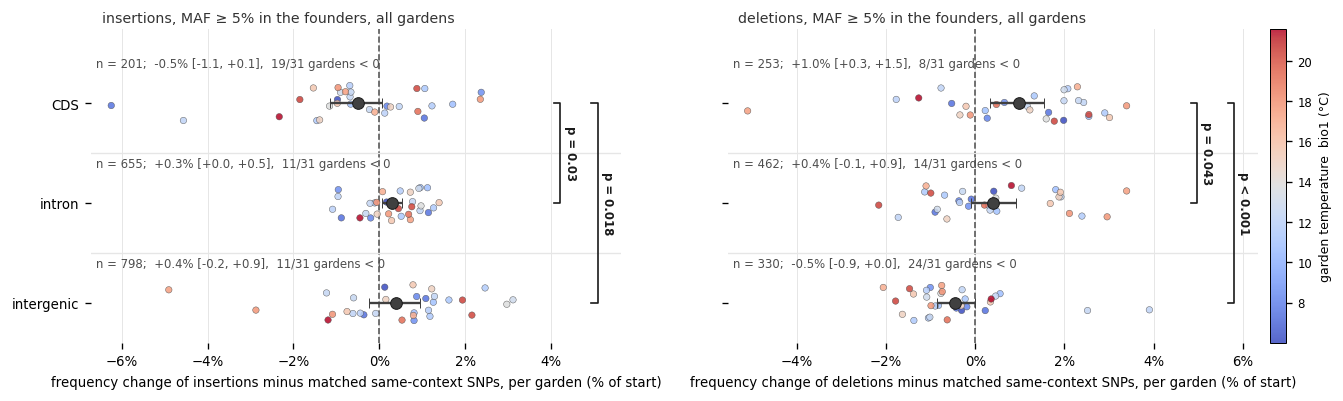

      kind    context  n_events    mean  boot_lo  boot_hi  ci_excludes_0  gardens_below  matched_snp_null_p
insertions        CDS       201 -0.0050  -0.0114   0.0006          False             19               0.513
insertions     intron       655  0.0030   0.0005   0.0054           True             11               0.381
insertions intergenic       798  0.0039  -0.0024   0.0094          False             11               0.330
 deletions        CDS       253  0.0099   0.0034   0.0154           True              8               0.028
 deletions     intron       462  0.0041  -0.0009   0.0090          False             14               0.291
 deletions intergenic       330 -0.0045  -0.0085   0.0000          False             24               0.286

coding sequence against the two non-coding contexts, within each SV type (difference of the matched differences):
      kind         contrast  mean_diff  boot_lo  boot_hi  gardens_below  wilcoxon_p  significant  matched_snp_null_p
insertions  

In [5]:

T,_=lead_figure(stat_freq,COMMON,"MAF ≥ 5% in the founders, all gardens",XF,True,"main_fig2_lead_frequency_maf5.png",tag="1b frequency, MAF>=5%")
show(T)


### 1c. Frequency change, precision-weighted — all variants (top) and MAF ≥ 5% (bottom)

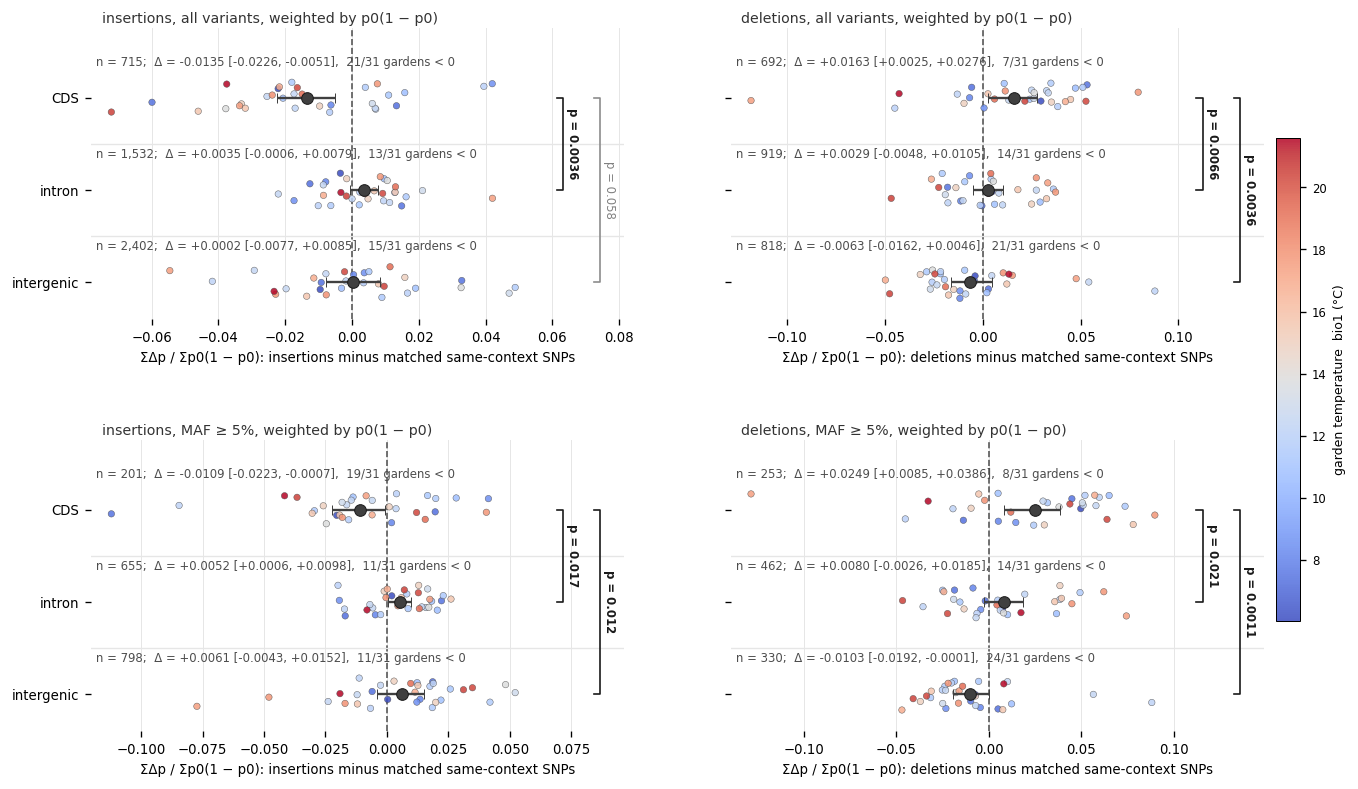

all variants:
      kind    context  n_events    mean  boot_lo  boot_hi  ci_excludes_0  gardens_below  matched_snp_null_p
insertions        CDS       715 -0.0135  -0.0226  -0.0051           True             21               0.285
insertions     intron      1532  0.0035  -0.0006   0.0079          False             13               0.564
insertions intergenic      2402  0.0002  -0.0077   0.0085          False             15               0.969
 deletions        CDS       692  0.0163   0.0025   0.0276           True              7               0.124
 deletions     intron       919  0.0029  -0.0048   0.0105          False             14               0.702
 deletions intergenic       818 -0.0063  -0.0162   0.0046          False             21               0.454

coding sequence against the two non-coding contexts, within each SV type (difference of the matched differences):
      kind         contrast  mean_diff  boot_lo  boot_hi  gardens_below  wilcoxon_p  significant  matched_snp_null_

  all      insertions intergenic  r = 0.994   1c/1a =  0.38   Σp0(1−p0)/Σp0 = 0.64
  all      deletions  CDS         r = 0.998   1c/1a =  2.29   Σp0(1−p0)/Σp0 = 0.40
  all      deletions  intron      r = 0.998   1c/1a =  1.78   Σp0(1−p0)/Σp0 = 0.50
  all      deletions  intergenic  r = 1.000   1c/1a =  2.32   Σp0(1−p0)/Σp0 = 0.44


  MAF>=5%  insertions CDS         r = 0.998   1c/1a =  2.17   Σp0(1−p0)/Σp0 = 0.54
  MAF>=5%  insertions intron      r = 0.996   1c/1a =  1.76   Σp0(1−p0)/Σp0 = 0.52
  MAF>=5%  insertions intergenic  r = 0.999   1c/1a =  1.55   Σp0(1−p0)/Σp0 = 0.58
  MAF>=5%  deletions  CDS         r = 1.000   1c/1a =  2.51   Σp0(1−p0)/Σp0 = 0.38
  MAF>=5%  deletions  intron      r = 0.999   1c/1a =  1.97   Σp0(1−p0)/Σp0 = 0.48
  MAF>=5%  deletions  intergenic  r = 1.000   1c/1a =  2.28   Σp0(1−p0)/Σp0 = 0.44


In [6]:

XW="ΣΔp / Σp0(1 − p0): {kind} minus matched same-context SNPs"
fig,ax=plt.subplots(2,2,figsize=(13,7.6),sharey=True,gridspec_kw=dict(hspace=0.42))
T1,sc_=lead_figure(stat_freqw,ALLV,"all variants, weighted by p0(1 − p0)",XW,False,"",axes=ax[0],tag="1c weighted frequency, all",sym="Δ")
T2,sc_=lead_figure(stat_freqw,COMMON,"MAF ≥ 5%, weighted by p0(1 − p0)",XW,False,"",axes=ax[1],tag="1c weighted frequency, MAF>=5%",sym="Δ")
cb=fig.colorbar(sc_,ax=ax,pad=0.01,fraction=0.02); cb.set_label("garden temperature  bio1 (°C)",fontsize=7.5); cb.ax.tick_params(labelsize=7)
fig.savefig(f"{G}/plots/main_fig2_lead_frequency_weighted.png",dpi=200,bbox_inches="tight"); plt.show()
show(T1,"all variants"); show(T2,"MAF >= 5%")
# how 1c relates to 1a/1b: same numerator (summed frequency change), different denominator
print("\n1c against 1a / 1b, garden by garden (Pearson r over the 31 gardens; ratio of the means; share of the class's summed p0 that is p0(1-p0)):")
for lab,flt in (("all",ALLV),("MAF>=5%",COMMON)):
    for k in ("ins","del"):
        for ctx in SUMC:
            ci=CTX.index(ctx); ms=(KD==k)&(CX==ci)&flt; mn=(KD=="snp")&(CX==ci)&flt; a_=load_diff(ms,mn); si,w,_=matched_snps(ms,mn); im=np.where(ms)[0]; b_=_wf(im,np.ones(im.size))-_wf(si,w)
            print(f"  {lab:<8} {KL[k]:<10} {ctx:<11} r = {np.corrcoef(a_,b_)[0,1]:.3f}   1c/1a = {b_.mean()/a_.mean():5.2f}   Σp0(1−p0)/Σp0 = {W0[im].sum()/P0[im].sum():.2f}")


### 2a. Selection coefficient — all variants

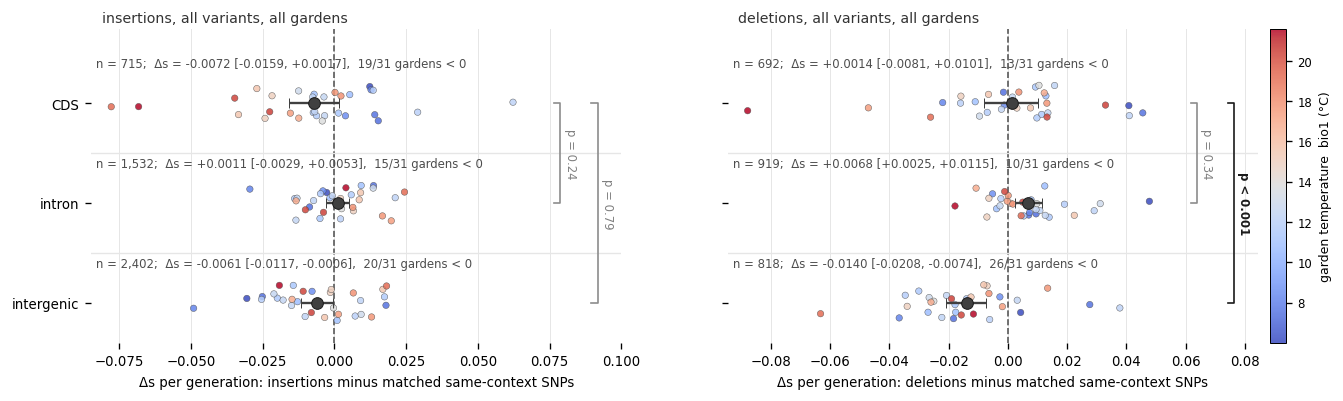

      kind    context  n_events    mean  boot_lo  boot_hi  ci_excludes_0  gardens_below  matched_snp_null_p
insertions        CDS       715 -0.0072  -0.0159   0.0017          False             19               0.349
insertions     intron      1532  0.0011  -0.0029   0.0053          False             15               0.783
insertions intergenic      2402 -0.0061  -0.0117  -0.0006           True             20               0.072
 deletions        CDS       692  0.0014  -0.0081   0.0101          False             13               0.803
 deletions     intron       919  0.0068   0.0025   0.0115           True             10               0.217
 deletions intergenic       818 -0.0140  -0.0208  -0.0074           True             26               0.011

coding sequence against the two non-coding contexts, within each SV type (difference of the matched differences):
      kind         contrast  mean_diff  boot_lo  boot_hi  gardens_below  wilcoxon_p  significant  matched_snp_null_p
insertions  

In [7]:

T,_=lead_figure(stat_s,ALLV,"all variants, all gardens",XS,False,"main_fig2_lead_selection_coefficient.png",tag="2a s, all")
show(T)


### 2b. Selection coefficient — MAF ≥ 5%

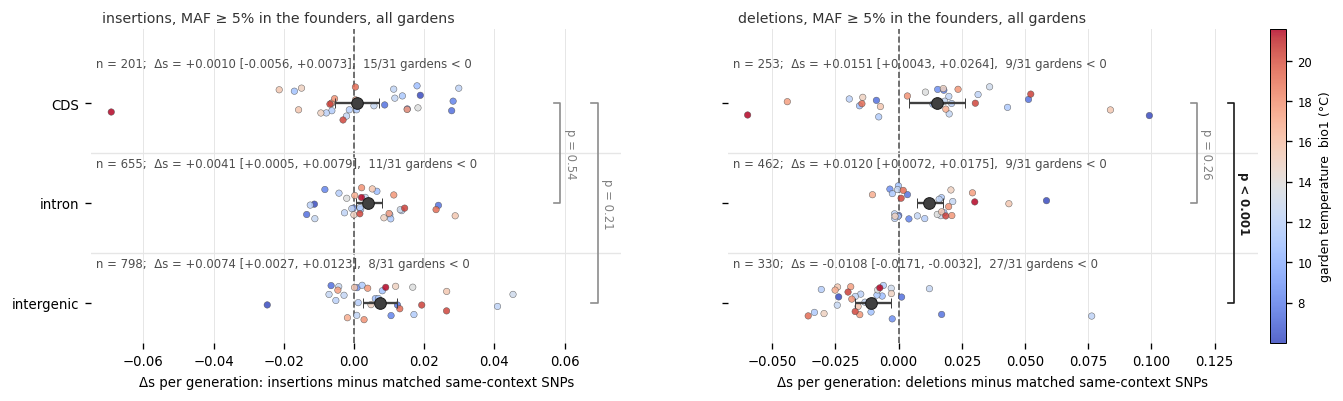

      kind    context  n_events    mean  boot_lo  boot_hi  ci_excludes_0  gardens_below  matched_snp_null_p
insertions        CDS       201  0.0010  -0.0056   0.0073          False             15               0.903
insertions     intron       655  0.0041   0.0005   0.0079           True             11               0.303
insertions intergenic       798  0.0074   0.0027   0.0123           True              8               0.063
 deletions        CDS       253  0.0151   0.0043   0.0264           True              9               0.038
 deletions     intron       462  0.0120   0.0072   0.0175           True              9               0.014
 deletions intergenic       330 -0.0108  -0.0171  -0.0032           True             27               0.059

coding sequence against the two non-coding contexts, within each SV type (difference of the matched differences):
      kind         contrast  mean_diff  boot_lo  boot_hi  gardens_below  wilcoxon_p  significant  matched_snp_null_p
insertions  

In [8]:

T,_=lead_figure(stat_s,COMMON,"MAF ≥ 5% in the founders, all gardens",XS,False,"main_fig2_lead_selection_coefficient_maf5.png",tag="2b s, MAF>=5%")
show(T)


### 2c. Selection coefficient, precision-weighted — all variants (top) and MAF ≥ 5% (bottom)

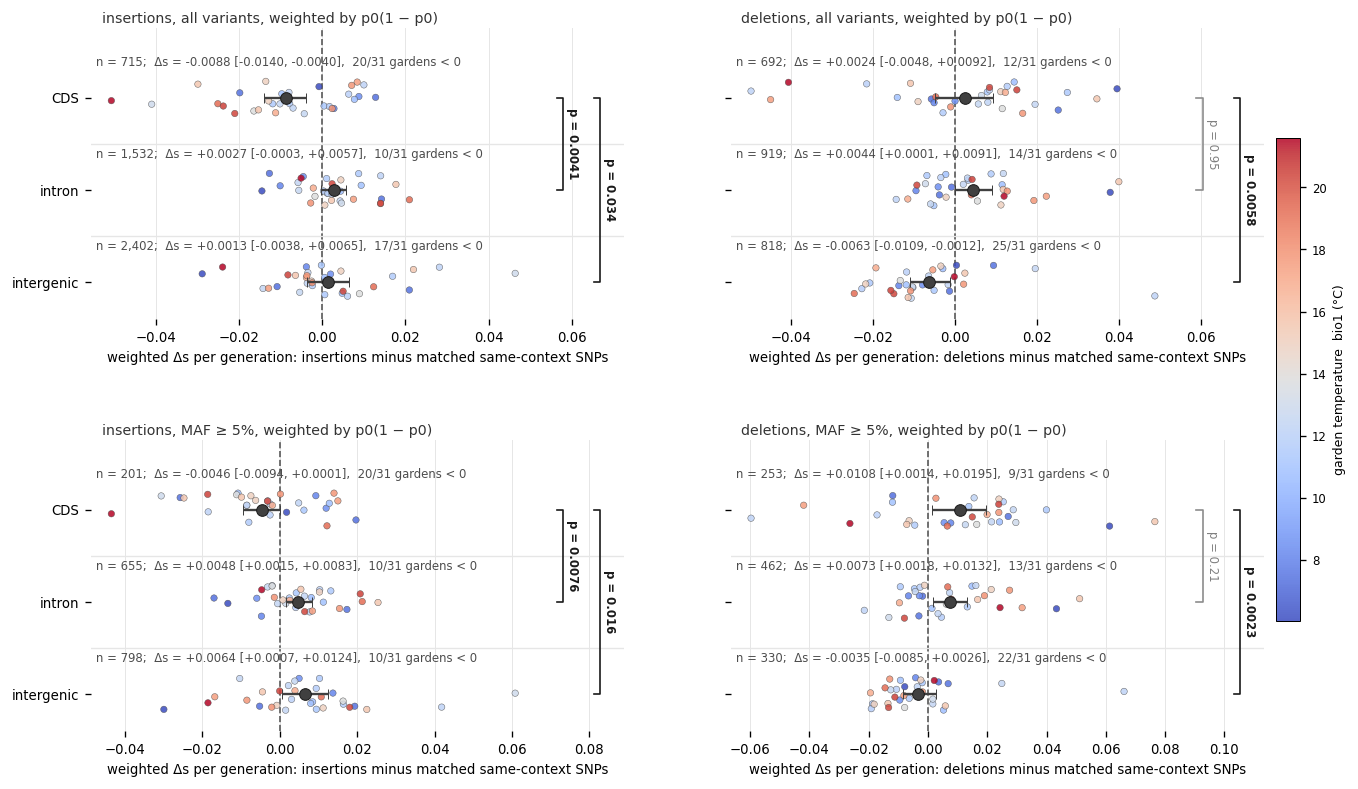

all variants:
      kind    context  n_events    mean  boot_lo  boot_hi  ci_excludes_0  gardens_below  matched_snp_null_p
insertions        CDS       715 -0.0088  -0.0140  -0.0040           True             20               0.178
insertions     intron      1532  0.0027  -0.0003   0.0057          False             10               0.375
insertions intergenic      2402  0.0013  -0.0038   0.0065          False             17               0.619
 deletions        CDS       692  0.0024  -0.0048   0.0092          False             12               0.626
 deletions     intron       919  0.0044   0.0001   0.0091           True             14               0.265
 deletions intergenic       818 -0.0063  -0.0109  -0.0012           True             25               0.132

coding sequence against the two non-coding contexts, within each SV type (difference of the matched differences):
      kind         contrast  mean_diff  boot_lo  boot_hi  gardens_below  wilcoxon_p  significant  matched_snp_null_

In [9]:

fig,ax=plt.subplots(2,2,figsize=(13,7.6),sharey=True,gridspec_kw=dict(hspace=0.42))
T1,sc_=lead_figure(stat_sw,ALLV,"all variants, weighted by p0(1 − p0)","weighted "+XS,False,"",axes=ax[0],tag="2c weighted s, all")
T2,sc_=lead_figure(stat_sw,COMMON,"MAF ≥ 5%, weighted by p0(1 − p0)","weighted "+XS,False,"",axes=ax[1],tag="2c weighted s, MAF>=5%")
cb=fig.colorbar(sc_,ax=ax,pad=0.01,fraction=0.02); cb.set_label("garden temperature  bio1 (°C)",fontsize=7.5); cb.ax.tick_params(labelsize=7)
fig.savefig(f"{G}/plots/main_fig2_lead_selection_coefficient_weighted.png",dpi=200,bbox_inches="tight"); plt.show()
show(T1,"all variants"); show(T2,"MAF >= 5%")


### Summary — coding insertions and coding deletions across the six versions

In [10]:

S_=pd.concat(SUMMARY); S_=S_[S_.context=="CDS"].copy()
S_["estimate [95% CI]"]=[(f"{100*m:+.1f}% [{100*l:+.1f}, {100*h:+.1f}]" if f[:2] in ("1a","1b") else f"{m:+.4f} [{l:+.4f}, {h:+.4f}]") for f,m,l,h in zip(S_.figure,S_["mean"],S_.boot_lo,S_.boot_hi)]
for k in ("insertions","deletions"):
    print(f"CDS {k} vs matched CDS SNPs"); print(S_[S_.kind==k][["figure","n_events","estimate [95% CI]","ci_excludes_0","gardens_below","matched_snp_null_p"]].to_string(index=False)); print()
C_=pd.concat(CONTRASTS); C_["difference [95% CI]"]=[(f"{100*m:+.1f}% [{100*l:+.1f}, {100*h:+.1f}]" if f[:2] in ("1a","1b") else f"{m:+.4f} [{l:+.4f}, {h:+.4f}]") for f,m,l,h in zip(C_.figure,C_.mean_diff,C_.boot_lo,C_.boot_hi)]
for k in ("insertions","deletions"):
    for c in ("CDS - intron","CDS - intergenic"):
        print(f"{k}: {c}"); print(C_[(C_.kind==k)&(C_.contrast==c)][["figure","difference [95% CI]","gardens_below","wilcoxon_p","significant","matched_snp_null_p"]].to_string(index=False)); print()


CDS insertions vs matched CDS SNPs
                        figure  n_events          estimate [95% CI]  ci_excludes_0  gardens_below  matched_snp_null_p
             1a frequency, all       715         -0.7% [-1.2, -0.2]           True             21               0.385
         1b frequency, MAF>=5%       201         -0.5% [-1.1, +0.1]          False             19               0.513
    1c weighted frequency, all       715 -0.0135 [-0.0226, -0.0051]           True             21               0.285
1c weighted frequency, MAF>=5%       201 -0.0109 [-0.0223, -0.0007]           True             19               0.434
                     2a s, all       715 -0.0072 [-0.0159, +0.0017]          False             19               0.349
                 2b s, MAF>=5%       201 +0.0010 [-0.0056, +0.0073]          False             15               0.903
            2c weighted s, all       715 -0.0088 [-0.0140, -0.0040]           True             20               0.178
        2c weighted s

## Figure 2 — GrENE-Net: is the selection still acting?

kMate estimates, for every pooled sample, the founder (ecotype) composition *h* from the k-mers and
derives each variant's allele frequency from it; within GrENE-Net a variant therefore moves with the
founders that carry it. The test of selection on SVs is at the founder level (a–b); (c–d) show the
same experiment at the level of the variants themselves, using kMate's stored per-pool allele
frequencies (`_sv_garden_af.py`): the founding frequency is the mean of the 8 seed-mix runs, and a
garden's frequency is the mean over its plots of each plot's frequency at its last sampled generation
(352 pools, 31 gardens). An SV event's frequency is the sum of its alleles' frequencies (capped at 1).

**(a)** Founder burden. For each founder *f*, mean log-fitness over the 31 gardens,
*y*<sub>*f*</sub> = mean<sub>*s*</sub> log[(*H*<sub>0,*f*</sub> + Δ*H*<sub>*s*,*f*</sub> + 10⁻⁵) /
(*H*<sub>0,*f*</sub> + 10⁻⁵)], with *H*<sub>0</sub> the founding ecotype frequency (mean of 8 seed-mix
estimates) and *H*<sub>0</sub> + Δ*H*<sub>*s*</sub> the last-generation ecotype frequency in garden *s*
(plots equally weighted). The mixed model, fit by REML, is

> *y* = β₀ + β₁·z(*r*<sub>context</sub>) + β₂·z(*r*<sub>intergenic</sub>) + β₃·z(call rate, SVs) +
> β₄·z(call rate, SNPs) + β₅·[sequencing route] + *u* + ε,  *u* ~ N(0, σ²<sub>g</sub>**K**),
> ε ~ N(0, σ²<sub>e</sub>**I**)

where *r*<sub>context</sub> = (variants of the class carried) / (variants of the class called) for
the founder, *r*<sub>intergenic</sub> the same for intergenic variants of the same kind and origin
(the within-class baseline), z(·) standardises to unit SD, and **K** is the SNP kinship matrix
(standardised GRM from a 2% SNP draw). Shown: β₁ ± 1.96 SE (Wald), shared variants (carried by both
cold- and warm-origin founders), per context and variant kind. **(b)** The same relation in the raw
data: founder mean log-fitness against the standardised shared-CDS-insertion burden, one point per
founder coloured by origin temperature, with the OLS line and 95% band (the mixed model in (a) adds
the covariates and the kinship term). **(c)** Frequency change against matched SNPs. For each CDS insertion, its allele-frequency change from
the seed mix to the garden minus the mean change of its matched SNPs: the CDS SNPs carried by the same
number of founders and by founders of the same origin-climate quintile, so SNPs that started at the same
frequency on the same kind of founder background. The 715 differences are averaged and expressed relative
to the insertions' starting frequency. One
dot per garden against the garden's temperature: purifying selection shows as an offset below zero
across the whole range, lineage sorting would show as a slope. Solid line and band = mean ± 95% CI over
gardens; dotted = OLS on temperature; deletions alongside. The p-value is **empirical**:
gardens share one founder pool and are not independent, so the observed mean is compared with 1,000
random sets of CDS SNPs, one per insertion drawn from its matched SNPs
(one-sided for insertions, two-sided for deletions). **(d)** Climate of origin × garden climate. For variants private
to cold-origin or to warm-origin founders, the log load change per garden, log[*L*<sub>garden</sub>/*L*<sub>0</sub>],
regressed on garden temperature (OLS over 31 gardens; slope ± 1.96 SE), for insertions, deletions,
short indels and SNPs alike. A negative slope = the class loses more in warmer gardens.

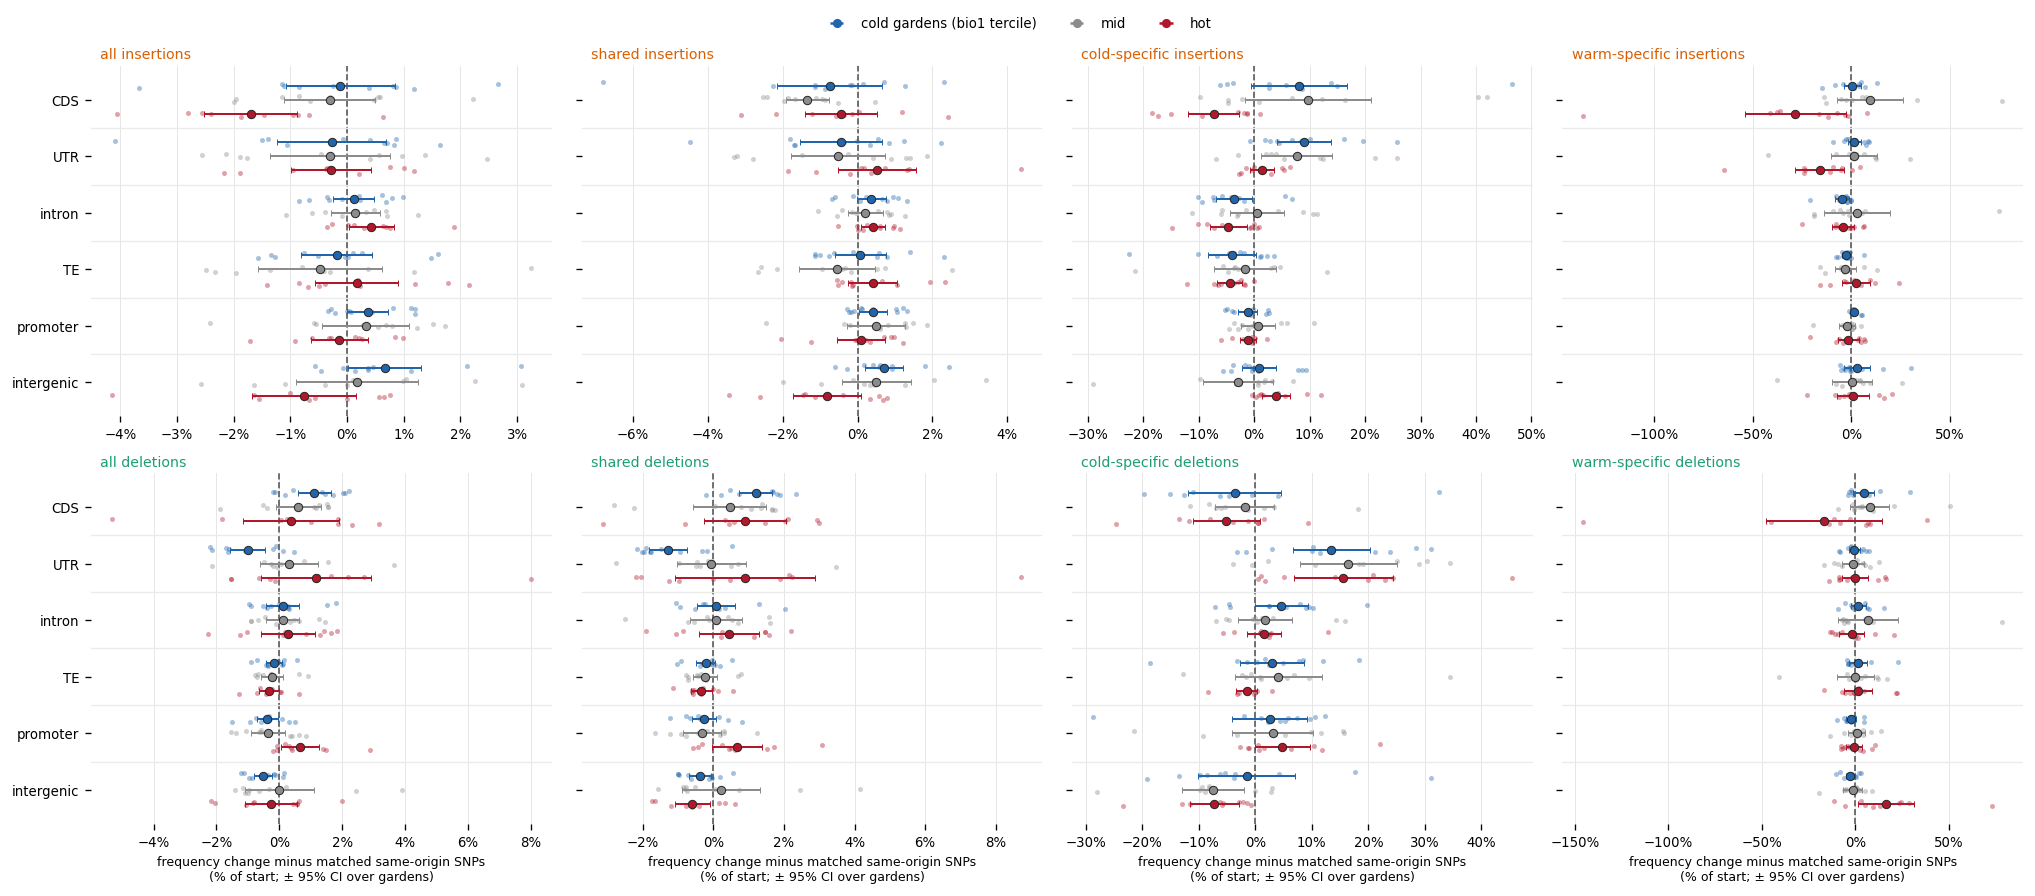

Supplement to 2c  all gardens: mean log load change vs same-origin matched SNPs of the same context, gardens below 0 (of 31), two-sided matched-SNP null p
origin                    all  shared  cold-specific  warm-specific
kind       context                                                 
deletions  CDS         0.0071  0.0087        -0.0357        -0.0140
           TE         -0.0024 -0.0026         0.0187         0.0104
           UTR         0.0012 -0.0018         0.1511        -0.0072
           intergenic -0.0027 -0.0026        -0.0531         0.0377
           intron      0.0016  0.0020         0.0271         0.0201
           promoter   -0.0004  0.0002         0.0344        -0.0095
insertions CDS        -0.0069 -0.0084         0.0363        -0.0590
           TE         -0.0017 -0.0002        -0.0339        -0.0121
           UTR        -0.0029 -0.0015         0.0615        -0.0430
           intergenic  0.0005  0.0015         0.0063         0.0133
           intron      0.0022

In [14]:

ZC={"cold":"#2166AC","mid":"0.55","hot":"#B2182B"}; ZOFF={"cold":-0.25,"mid":0.0,"hot":0.25}
ORIG=(("all",None),("shared","shared"),("cold-specific","cold-specific"),("warm-specific","warm-specific"))
fig,ax=plt.subplots(2,4,figsize=(17,7.2),sharey=True); rows=[]
for r,k in enumerate(("ins","del")):
    for c_,(lab,o) in enumerate(ORIG):
        a=ax[r,c_]; style(a,axis="x"); a.axvline(0,color="0.35",lw=1,ls="--")
        mo=np.ones(KD.size,bool) if o is None else (ORG==o)
        for yi,ctx in enumerate(CTX):
            ms=mo&(KD==k)&(CX==yi); mn=mo&(KD=="snp")&(CX==yi); d=load_diff(ms,mn)
            pe=null_p(d.mean(),matched_null(ms,mn),two_sided=True)
            for z in ("cold","mid","hot"):
                dz=d[ZN==z]; a.scatter(dz,yi+ZOFF[z]+rng.uniform(-0.06,0.06,dz.size),s=9,color=ZC[z],alpha=0.4,linewidth=0,zorder=2)   # one dot per garden
                a.errorbar(dz.mean(),yi+ZOFF[z],xerr=1.96*dz.std(ddof=1)/np.sqrt(dz.size),fmt="o",ms=5,color=ZC[z],mec="0.15",mew=0.6,capsize=2,elinewidth=1.2,zorder=3)
                rows.append(dict(kind=KL[k],origin=lab,context=ctx,zone=z,mean=dz.mean(),gardens_below=int((dz<0).sum()),n_gardens=int(dz.size)))
            rows.append(dict(kind=KL[k],origin=lab,context=ctx,zone="all",mean=d.mean(),gardens_below=int((d<0).sum()),n_gardens=31,n_events=int(ms.sum()),n_snps=int(mn.sum()),null_p_two_sided=pe))
            if yi<5: a.axhline(yi+0.5,color="0.92",lw=0.8)
        a.set_yticks(range(6)); a.set_yticklabels(CTX); a.set_ylim(5.6,-0.6)
        a.annotate(f"{lab} {KL[k]}",xy=(0.02,1.02),xycoords="axes fraction",fontsize=8.5,color=KC[k])
        a.xaxis.set_major_formatter(PercentFormatter(1.0,decimals=0))
        if r==1: a.set_xlabel("frequency change minus matched same-origin SNPs\n(% of start; ± 95% CI over gardens)",fontsize=7.5)
for z,l in (("cold","cold gardens (bio1 tercile)"),("mid","mid"),("hot","hot")): ax[0,0].errorbar([],[],xerr=[],fmt="o",ms=4.5,color=ZC[z],label=l)
fig.legend(frameon=False,fontsize=8,loc="lower center",bbox_to_anchor=(0.5,0.99),ncol=3)
fig.tight_layout(); fig.savefig(f"{G}/plots/supp_fig2c_by_origin.png",dpi=170); plt.show()
T=pd.DataFrame(rows); A=T[T.zone=="all"]
print("Supplement to 2c  all gardens: mean log load change vs same-origin matched SNPs of the same context, gardens below 0 (of 31), two-sided matched-SNP null p")
print(A.pivot_table(index=["kind","context"],columns="origin",values="mean").reindex(columns=[o for o,_ in ORIG]).round(4).to_string())
print(); print(A.pivot_table(index=["kind","context"],columns="origin",values="gardens_below").reindex(columns=[o for o,_ in ORIG]).astype(int).to_string())
print(); print(A.pivot_table(index=["kind","context"],columns="origin",values="null_p_two_sided").reindex(columns=[o for o,_ in ORIG]).round(3).to_string())
print("\nby garden zone (mean):"); print(T[T.zone!="all"].pivot_table(index=["kind","context","origin"],columns="zone",values="mean").reindex(columns=["cold","mid","hot"]).round(4).to_string())


### Summary of the context control — all insertions and deletions, coding vs intron vs intergenic

The same statistic for all insertions and all deletions (any climate of origin) in the three contexts that make the
contrast: coding sequence, introns and intergenic sequence, for each event, its frequency change minus the
mean change of its matched SNPs (same context, same number of carrier founders, same origin-climate
quintile), averaged over the class and expressed relative to the class's starting frequency. Small dots = gardens; large points = zone
mean with a 95% percentile bootstrap CI (2,000 resamples of the zone's gardens).

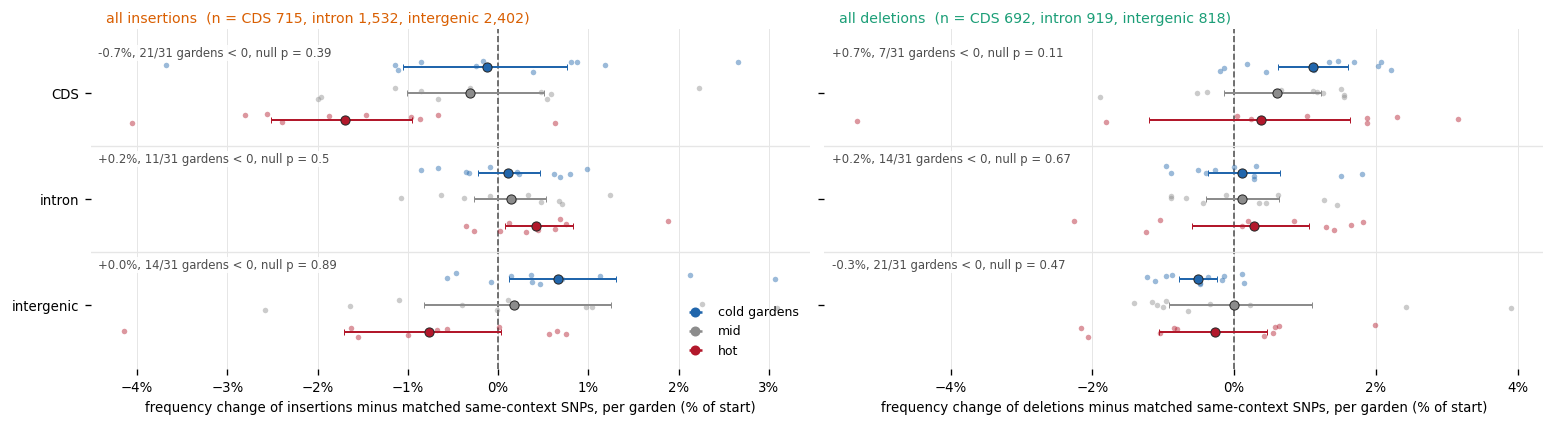

      kind    context  n_events  n_snps    mean  boot_lo  boot_hi  gardens_below  null_p_two_sided
insertions        CDS       715   58560 -0.0069  -0.0125  -0.0018             21             0.385
insertions     intron      1532   55465  0.0022   0.0001   0.0045             11             0.496
insertions intergenic      2402   30992  0.0005  -0.0049   0.0058             14             0.894
 deletions        CDS       692   58560  0.0071   0.0011   0.0120              7             0.107
 deletions     intron       919   55465  0.0016  -0.0022   0.0053             14             0.667
 deletions intergenic       818   30992 -0.0027  -0.0070   0.0020             21             0.471


In [15]:

def bci(v,B=2000,seed=2):
    # percentile bootstrap CI of the mean over gardens (resample gardens with replacement)
    r=np.random.default_rng(seed); bs=r.choice(v,(B,v.size)).mean(1); return np.percentile(bs,2.5),np.percentile(bs,97.5)
SUMC=["CDS","intron","intergenic"]; fig,ax=plt.subplots(1,2,figsize=(13,3.6),sharey=True); rows=[]
for a,k in zip(ax,("ins","del")):
    style(a,axis="x"); a.axvline(0,color="0.35",lw=1,ls="--")
    for yi,ctx in enumerate(SUMC):
        ci=CTX.index(ctx); ms=(KD==k)&(CX==ci); mn=(KD=="snp")&(CX==ci); d=load_diff(ms,mn); pe=null_p(d.mean(),matched_null(ms,mn),two_sided=True)
        for z in ("cold","mid","hot"):
            dz=d[ZN==z]; a.scatter(dz,yi+ZOFF[z]+rng.uniform(-0.06,0.06,dz.size),s=11,color=ZC[z],alpha=0.45,linewidth=0,zorder=2)
            lo,hi=bci(dz); a.errorbar(dz.mean(),yi+ZOFF[z],xerr=[[dz.mean()-lo],[hi-dz.mean()]],fmt="o",ms=5.5,color=ZC[z],mec="0.15",mew=0.6,capsize=2,elinewidth=1.2,zorder=3)
        lo,hi=bci(d); rows.append(dict(kind=KL[k],context=ctx,n_events=int(ms.sum()),n_snps=int(mn.sum()),mean=d.mean(),boot_lo=lo,boot_hi=hi,gardens_below=int((d<0).sum()),null_p_two_sided=pe))
        a.annotate(f"{100*d.mean():+.1f}%, {(d<0).sum()}/31 gardens < 0, null {pfmt(pe)}",xy=(0.01,yi-0.44),xycoords=("axes fraction","data"),ha="left",va="top",fontsize=7,color="0.3",bbox=dict(facecolor="white",alpha=0.85,edgecolor="none",pad=1))
        if yi<2: a.axhline(yi+0.5,color="0.9",lw=0.8)
    a.set_yticks(range(3)); a.set_yticklabels(SUMC,fontsize=8); a.set_ylim(2.6,-0.6)
    a.set_xlabel(f"frequency change of {KL[k]} minus matched same-context SNPs, per garden (% of start)",fontsize=8); a.xaxis.set_major_formatter(PercentFormatter(1.0,decimals=0))
    a.annotate(f"all {KL[k]}  (n = "+", ".join(f"{c} {int(((KD==k)&(CX==CTX.index(c))).sum()):,}" for c in SUMC)+")",xy=(0.02,1.02),xycoords="axes fraction",fontsize=8.5,color=KC[k])
for z,l in (("cold","cold gardens"),("mid","mid"),("hot","hot")): ax[0].errorbar([],[],xerr=[],fmt="o",ms=5,color=ZC[z],label=l)
ax[0].legend(frameon=False,fontsize=7.5,loc="lower right")
fig.tight_layout(); fig.savefig(f"{G}/plots/supp_fig2c_summary.png",dpi=200); plt.show()
print(pd.DataFrame(rows).round(4).to_string(index=False))


## Models and statistics, as run

- **Founder burden (Fig. 2a).** Linear mixed model above, REML by eigendecomposition of **K**
  (EMMA-style one-dimensional search for σ²<sub>g</sub>/σ²<sub>e</sub>), Wald z-tests. `_sv_burden_lmm.py`.
  Joint models add z(SNP CDS rate), z(SNP intergenic rate) [and the indel pair]. Robustness in the
  key-results notebook: permutation of the burden residual (1000×), per-garden fits, rare (2–10 carrier)
  events alone, shifted-annotation null (200 circular shifts, size-matched).
- **Allele frequencies in GrENE-Net (Fig. 2c–d, 3a–b).** kMate's stored per-pool allele frequencies
  (`common/results/pool_matrices/pool_gen9_*`: every plot at its last sampled generation, 352 pools) and
  the seed-mix founding frequency (mean of 8 runs, `af_store/p0_*`). Garden frequency = mean over the
  garden's plots. SV event = sum of its alleles' frequencies, capped at 1. SNPs a random 10% of records,
  short indels a random 10%; filters and labels as in the founder panel (`_sv_garden_af.py`).
- **Matched frequency change (Fig. 2c, 3a–b, supplements).** For each event *v* and garden *s*:
  Δ<sub>v</sub> = *p*<sub>v</sub>(garden) − *p*<sub>v</sub>(seed mix), minus the mean Δ of its matched SNPs
  — all SNPs of the same context (and origin class where stated) with the same carrier count and the
  same carrier-climate quintile (events whose exact cell holds no SNP use their carrier-count bin; none in
  CDS). The differences are averaged over the class and divided by the class's mean starting frequency,
  so the value is a percent of where the class began. Equivalently, the relative change of the summed
  class frequency minus that of the composition-matched SNP set. **Test:** 95% percentile bootstrap over
  the 31 gardens (2,000 resamples); the stricter matched-SNP null (1,000 random sets, one SNP per event
  from its matches, same statistic) is printed in the tables. Gardens share one founder pool, so garden
  counts ("21/31") are descriptive.
- **Origin × garden (Fig. 2d).** Origin labels from each variant's own carriers: cold-specific = ≥ 2
  cold-origin and 0 warm-origin carriers (origin tertiles of founder bio1: ≤ 8.26 °C cold, ≥ 10.72 °C
  warm), warm-specific the mirror. Per class and kind, log[*L*<sub>garden</sub>/*L*<sub>0</sub>] per
  garden, OLS on garden bio1 over 31 gardens.
- **Robustness (`_sv_main_figures_checks.py`).** Burden model with founder origin bio1 (and bio1²) as
  extra covariates: β₁ unchanged (−0.22); the burden–fitness relation holds within origin tertiles
  (cold ρ = −0.51, warm ρ = −0.27). Spectra without singletons (minor-allele count ≥ 2): same ordering
  (values printed under Figure 1).

### Two filters on the lead analysis — one-generation gardens, and dropping the seed-mix point

Two robustness filters on the same comparison as 1a–2c (each SV event against **all** SNPs of the same
context carried by the same number of founders and by founders of the same origin-climate quintile,
`matched_snps`, weighted so the SNP set has the events' composition).

**Filter 1 — generation coverage.** Gardens differ in how many generations were sampled: 19 gardens at
generations 1, 2 and 3; 7 at two; **5 at one only** (sites 23, 37, 33, 60, 26; bio1 7.3, 8.1, 12.2, 19.2,
21.6 °C). A one-generation garden contributes a selection coefficient fitted through exactly two points,
t = 0 (seed mix) and its single sampled generation, so its *s* is a pure function of *p*₀; in the
frequency statistic it has had one generation of selection against three for the 3-generation group.

**Filter 2 — the seed-mix point.** `GARDEN_STAT=gslope_no0` refits the garden-level selection
coefficient as the OLS slope of logit allele frequency on generation using **only the sampled
generations 1–3**, omitting t = 0. *p*₀ then enters the statistic nowhere (it remains only as the
*p*₀(1 − *p*₀) precision weight in the 2c variants, where it is a weight and not the quantity measured).
A slope needs ≥ 2 points, so the 5 one-generation gardens are NaN by construction and both columns below
are computed on the same 26 gardens. Written to `garden_sgslope_no0_event.npz`, same rows and row order
as `garden_sgslope_event.npz` (asserted on `kind` and `n`).

**Statistic.** Δ*s* = mean *s* of the class minus mean *s* of its matched SNPs, per garden; unweighted
counts every variant once (as 2a/2b), weighted uses *p*₀(1 − *p*₀) (as 2c).

**Two tests, answering different questions.**
- *gCI* — 95% percentile bootstrap of the mean over **gardens** (2,000 resamples of the 26 gardens), the
  interval used in 1a–2c. It holds the event set fixed, so it asks whether the offset is consistent
  across gardens.
- *eP* — two-sided empirical p from a 95% percentile bootstrap over **events** (300 resamples of the
  class's events with replacement, matched SNP set held fixed), which adds the variant-sampling
  dimension that the garden bootstrap omits. With a few hundred events this is the wider of the two.

No correction for the number of cells in the table.

gardens by sampled generations: {1: 5, 2: 7, 3: 19}; one-generation gardens dropped by the no-t0 fit: [23, 37, 33, 60, 26]



insertions: garden-level selection coefficient vs matched same-context SNPs, 26 gardens with >= 2 sampled generations
   context              statistic  n_events                                   with t0                                     no t0
       CDS        unweighted, all       715 -0.0064 [-0.0122,-0.0005] eP=0.51 17/26<0 -0.0049 [-0.0156,+0.0057] eP=0.46 14/26<0
       CDS    unweighted, MAF>=5%       201 +0.0005 [-0.0038,+0.0047] eP=0.83 14/26<0 -0.0049 [-0.0147,+0.0042] eP=0.73 15/26<0
       CDS p0(1-p0)-weighted, all       715 -0.0086 [-0.0134,-0.0041] eP=0.41 18/26<0 -0.0098 [-0.0197,-0.0013] eP=0.33 16/26<0
    intron        unweighted, all      1532 +0.0009 [-0.0026,+0.0045] eP=0.83 13/26<0 +0.0037 [-0.0018,+0.0100] eP=0.45 14/26<0
    intron    unweighted, MAF>=5%       655  +0.0048 [+0.0012,+0.0087] eP=0.37 8/26<0  +0.0053 [-0.0008,+0.0118] eP=0.39 8/26<0
    intron p0(1-p0)-weighted, all      1532  +0.0029 [+0.0003,+0.0058] eP=0.58 7/26<0 +0.0033 [-0.0014,+0.0082] e

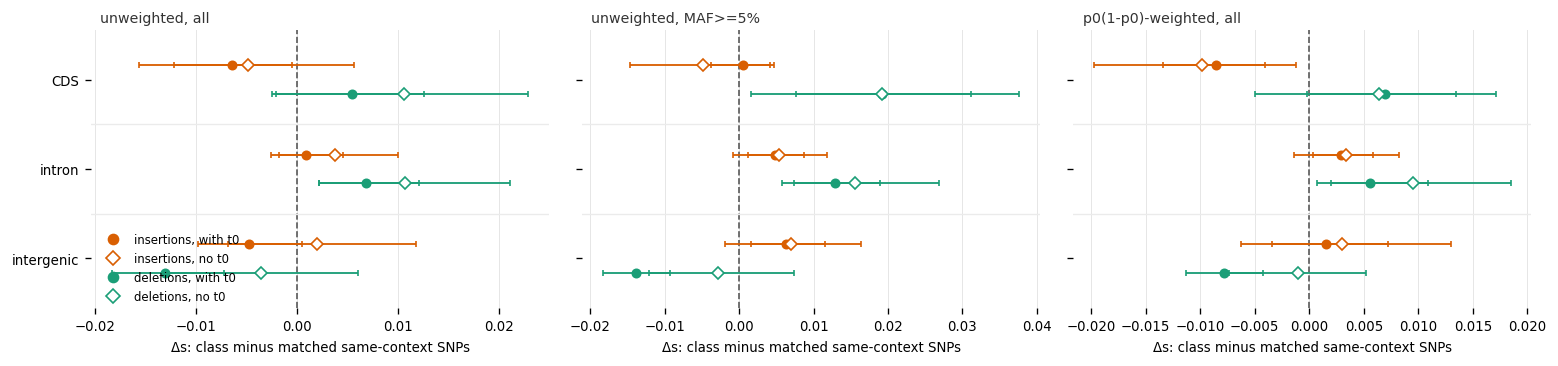

In [ ]:

PMD=os.path.abspath(os.path.join(G,"..","..","..","common","results","pool_matrices"))
NGEN={}
for _g in (1,2,3):
    for _s in pd.read_csv(f"{PMD}/pool_gen{_g}_nonsnp.meta.csv").site.unique(): NGEN.setdefault(_s,set()).add(_g)
NGN=np.array([len(NGEN[s]) for s in GS["sites"]])
B0=np.load(f"{G}/garden_sgslope_no0_event.npz")
assert np.array_equal(B0["kind"].astype(str),KD) and np.array_equal(B0["n"],GS["n"])
SNO=B0["p"][:,1:].astype(np.float64)                      # selection coefficient without the seed-mix point
OKG=~np.isnan(SNO).all(0)                                 # the 26 gardens with >= 2 sampled generations
assert set(GS["sites"][~OKG])==set(GS["sites"][NGN==1])
print(f"gardens by sampled generations: {dict(zip(*[x.tolist() for x in np.unique(NGN,return_counts=True)]))}; "
      f"one-generation gardens dropped by the no-t0 fit: {GS['sites'][~OKG].tolist()}")

def _mkwm(MAT):
    def wm(i,w):
        ok=~np.isnan(MAT[i]); den=(w[:,None]*ok).sum(0); return np.nansum(MAT[i]*w[:,None],0)/np.where(den>0,den,np.nan)
    return lambda i,si,w,W: wm(i,W[i])-wm(si,w*W[si])
_st0,_sno=_mkwm(SS),_mkwm(SNO)
_rg=np.random.default_rng(0)
def cmp_row(kind,ctx,W,flt):
    ci=CTX.index(ctx); ms=(KD==kind)&(CX==ci)&flt; mn=(KD=="snp")&(CX==ci)&flt
    si,w,_=matched_snps(ms,mn); im=np.where(ms)[0]; out={}
    for tag,fn in (("with t0",_st0),("no t0",_sno)):
        d=fn(im,si,w,W)[OKG]
        bs=np.array([fn(_rg.choice(im,im.size),si,w,W)[OKG] for _ in range(300)]).mean(1)
        lo,hi=bci(d)
        out[tag]=dict(mean=d.mean(),gci_lo=lo,gci_hi=hi,eP=2*min((bs>=0).mean(),(bs<=0).mean()),below=int((d<0).sum()))
    return int(ms.sum()),out

ROWS=[];    FIG={}
for kind in ("ins","del"):
    for ctx in SUMC:
        for wlab,W,flt in (("unweighted, all",ONE,ALLV),("unweighted, MAF>=5%",ONE,COMMON),("p0(1-p0)-weighted, all",W0,ALLV)):
            n_,o=cmp_row(kind,ctx,W,flt); FIG[(kind,ctx,wlab)]=o
            ROWS.append(dict(kind=KL[kind],context=ctx,statistic=wlab,n_events=n_,
                             **{f"{t} {k}":o[t][k] for t in ("with t0","no t0") for k in ("mean","gci_lo","gci_hi","eP","below")}))
TN=pd.DataFrame(ROWS)
for k in ("insertions","deletions"):
    print(f"\n{k}: garden-level selection coefficient vs matched same-context SNPs, 26 gardens with >= 2 sampled generations")
    sub=TN[TN.kind==k].copy()
    sub["with t0"]=[f"{m:+.4f} [{l:+.4f},{h:+.4f}] eP={p:.2f} {b}/26<0" for m,l,h,p,b in
                    zip(sub["with t0 mean"],sub["with t0 gci_lo"],sub["with t0 gci_hi"],sub["with t0 eP"],sub["with t0 below"])]
    sub["no t0"]=[f"{m:+.4f} [{l:+.4f},{h:+.4f}] eP={p:.2f} {b}/26<0" for m,l,h,p,b in
                  zip(sub["no t0 mean"],sub["no t0 gci_lo"],sub["no t0 gci_hi"],sub["no t0 eP"],sub["no t0 below"])]
    print(sub[["context","statistic","n_events","with t0","no t0"]].to_string(index=False))

print("\ncoding sequence against the two non-coding contexts (difference of the class-minus-matched-SNP means):")
for kind in ("ins","del"):
    for wlab in ("unweighted, all","unweighted, MAF>=5%","p0(1-p0)-weighted, all"):
        for other in ("intron","intergenic"):
            a0=FIG[(kind,"CDS",wlab)]["with t0"]["mean"]-FIG[(kind,other,wlab)]["with t0"]["mean"]
            a1=FIG[(kind,"CDS",wlab)]["no t0"]["mean"]-FIG[(kind,other,wlab)]["no t0"]["mean"]
            print(f"  {KL[kind]:<10} {wlab:<24} CDS - {other:<11} with t0 {a0:+.4f}   no t0 {a1:+.4f}")

fig,ax=plt.subplots(1,3,figsize=(13,3.1),sharey=True)
for a,wlab in zip(ax,("unweighted, all","unweighted, MAF>=5%","p0(1-p0)-weighted, all")):
    style(a,axis="x"); a.axvline(0,color="0.35",lw=1,ls="--")
    for yi,ctx in enumerate(SUMC):
        for kind,off in (("ins",-0.16),("del",0.16)):
            for tag,mk_,fc in (("with t0","o",KC[kind]),("no t0","D","white")):
                o=FIG[(kind,ctx,wlab)][tag]
                a.errorbar(o["mean"],yi+off,xerr=[[o["mean"]-o["gci_lo"]],[o["gci_hi"]-o["mean"]]],fmt=mk_,ms=5,
                           mfc=fc,color=KC[kind],ecolor=KC[kind],elinewidth=1.1,capsize=2,zorder=3)
        if yi<2: a.axhline(yi+0.5,color="0.92",lw=0.8)
    a.set_yticks(range(3)); a.set_yticklabels(SUMC,fontsize=8); a.set_ylim(2.55,-0.55)
    a.set_xlabel("Δs: class minus matched same-context SNPs",fontsize=8)
    a.annotate(wlab,xy=(0.02,1.03),xycoords="axes fraction",fontsize=8.5,color="0.2")
ax[0].legend(handles=[Line2D([0],[0],marker="o",ls="none",color=KC["ins"],label="insertions, with t0"),
                      Line2D([0],[0],marker="D",ls="none",color=KC["ins"],mfc="white",label="insertions, no t0"),
                      Line2D([0],[0],marker="o",ls="none",color=KC["del"],label="deletions, with t0"),
                      Line2D([0],[0],marker="D",ls="none",color=KC["del"],mfc="white",label="deletions, no t0")],
             frameon=False,fontsize=7,loc="lower left",bbox_to_anchor=(0.0,-0.02))
fig.tight_layout(); fig.savefig(f"{G}/plots/main_fig2_lead_no_t0.png",dpi=200,bbox_inches="tight"); plt.show()


### Is the climate gradient selection on SVs, or founder sorting? — all events vs shared events

The per-garden statistic is the one plotted in 1a: for each SV event, its frequency change from the seed
mix minus the mean change of its matched SNPs (same context, same number of carrier founders, same
carrier-origin-climate quintile; `matched_snps`/`load_diff`), averaged over the class and divided by the
class's mean starting frequency. One dot per garden (31), regressed on the garden's mean annual
temperature (bio1) by ordinary least squares.

**Left column — all events.** **Right column — shared events only:** events carried by at least one
cold-origin *and* one warm-origin founder, compared with **shared** SNPs matched the same way. Within
GrENE-Net a variant moves with the founders carrying it, so an event private to cold-origin founders
rises in cold gardens and falls in warm ones purely because those founders do — and every variant they
carry moves with them. A shared event carries no net origin-climate signal, so founder sorting cannot
generate a climate gradient for it. Comparing the two columns is therefore the test of whether a climate
gradient in the matched statistic is selection acting on the SVs or the founders sorting by climate.

**Two p values per line, answering different questions.**
- *p(gardens)* — the OLS p of the slope over the 31 gardens. It holds the event set fixed, so it asks
  whether the trend is consistent across gardens.
- *p(events)* — two-sided empirical p from resampling the class's **events** with replacement 400 times
  (matched SNP set held fixed) and refitting the slope each time. This adds the variant-sampling
  dimension the OLS omits, and with a few hundred events it is much the wider of the two.

The scale of the confound being removed, for reference: the raw unmatched climate slope of the SNP
baseline is +0.40 to +0.47 % per °C in **every** context (+0.26 to +0.31 within shared SNPs), so the
matching is subtracting a gradient several times larger than any residual reported here.

No correction for the number of lines in the figure (6 per column).

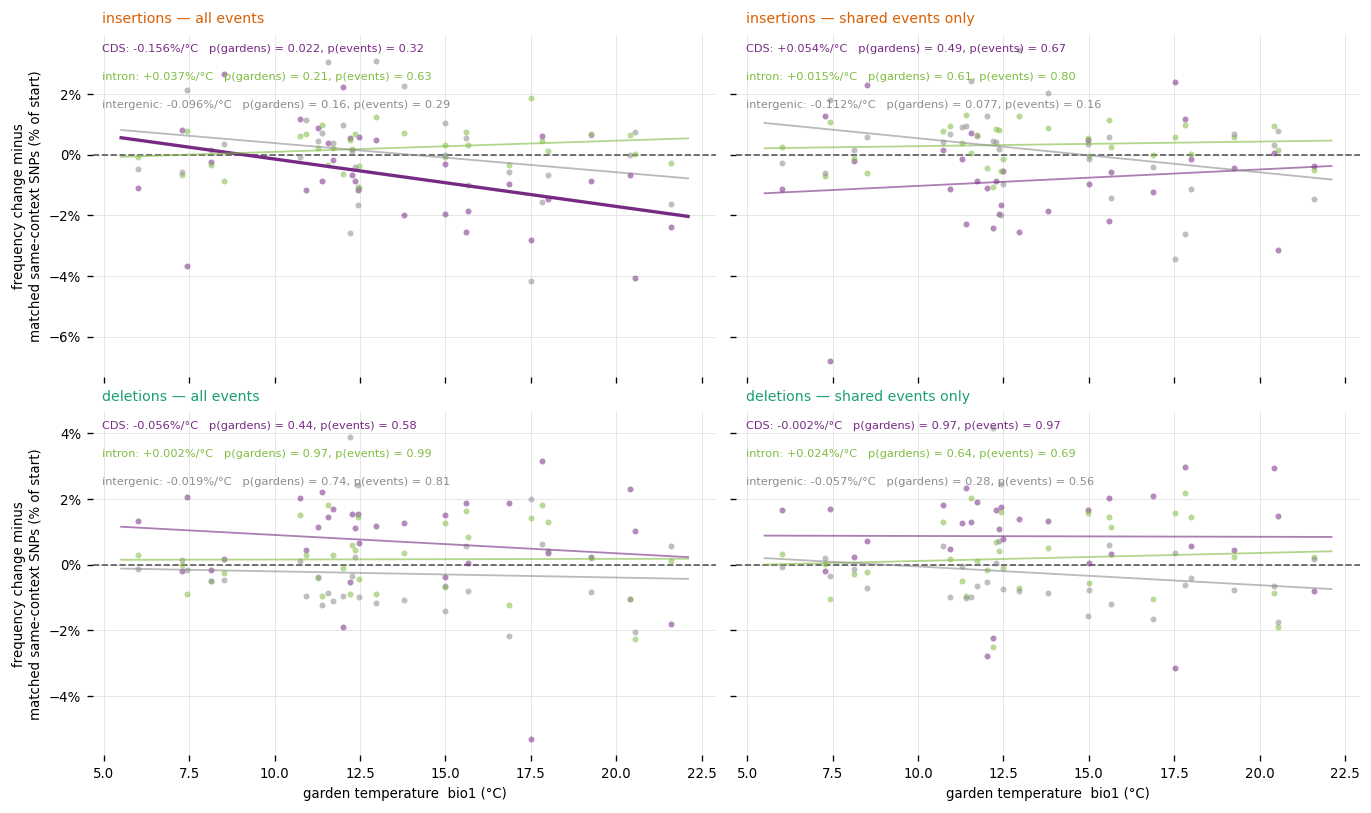


all events — zone means (terciles of garden bio1), all-garden mean, and the OLS slope on garden bio1
      kind    context  n_events     cold      mid      hot  mean_all  slope_per_C  p_gardens  p_events
insertions        CDS       715 -0.00117 -0.00310 -0.01701  -0.00690     -0.00156    0.02234     0.320
insertions     intron      1532  0.00114  0.00144  0.00423   0.00223      0.00037    0.20780     0.630
insertions intergenic      2402  0.00661  0.00176 -0.00760   0.00046     -0.00096    0.16122     0.295
 deletions        CDS       692  0.01112  0.00600  0.00374   0.00709     -0.00056    0.44424     0.580
 deletions     intron       919  0.00105  0.00112  0.00278   0.00163      0.00002    0.96721     0.990
 deletions intergenic       818 -0.00507 -0.00006 -0.00275  -0.00271     -0.00019    0.74292     0.810

shared events only — zone means (terciles of garden bio1), all-garden mean, and the OLS slope on garden bio1
      kind    context  n_events     cold      mid      hot  mean_al

In [ ]:

def load_diff_idx(idx,si,w):
    # load_diff for an arbitrary event index set against an already-built matched SNP set (for event bootstraps)
    Ls=np.nansum(PV[idx],0); Ln=np.nansum(PV[si]*w[:,None],0); return (Ls[1:]/Ls[0]-1)-(Ln[1:]/Ln[0]-1)

CCOL={"CDS":"#762A83","intron":"#7FBC41","intergenic":"0.55"}
SETS=(("all events",np.ones(KD.size,bool)),("shared events only",ORG=="shared"))
_rg2=np.random.default_rng(0); NBOOT=400
xg=np.linspace(BIO.min()-0.5,BIO.max()+0.5,50)
fig,ax=plt.subplots(2,2,figsize=(11.5,6.8),sharex=True,sharey="row")
CLIMROWS=[]
for ri,kind in enumerate(("ins","del")):
    for ci_,(slab,omask) in enumerate(SETS):
        a=ax[ri,ci_]; style(a); a.axhline(0,color="0.35",lw=1,ls="--")
        for k_,ctx in enumerate(SUMC):
            cidx=CTX.index(ctx); ms=omask&(KD==kind)&(CX==cidx); mn=omask&(KD=="snp")&(CX==cidx)
            d=load_diff(ms,mn); si,w,_=matched_snps(ms,mn); im=np.where(ms)[0]
            lr=stats.linregress(BIO,d)
            bsl=np.array([stats.linregress(BIO,load_diff_idx(_rg2.choice(im,im.size),si,w)).slope for _ in range(NBOOT)])
            pe=2*min((bsl>=0).mean(),(bsl<=0).mean())
            a.scatter(BIO,d,s=13,color=CCOL[ctx],alpha=0.55,linewidth=0,zorder=2)
            a.plot(xg,lr.intercept+lr.slope*xg,color=CCOL[ctx],lw=2.0 if lr.pvalue<0.05 else 1.1,
                   alpha=1.0 if lr.pvalue<0.05 else 0.6,zorder=3)
            a.annotate(f"{ctx}: {100*lr.slope:+.3f}%/°C   p(gardens) = {lr.pvalue:.2g}, p(events) = {pe:.2f}",
                       xy=(0.015,0.975-k_*0.082),xycoords="axes fraction",va="top",fontsize=6.8,color=CCOL[ctx])
            CLIMROWS.append(dict(event_set=slab,kind=KL[kind],context=ctx,n_events=int(ms.sum()),
                                 cold=d[ZN=="cold"].mean(),mid=d[ZN=="mid"].mean(),hot=d[ZN=="hot"].mean(),
                                 mean_all=d.mean(),slope_per_C=lr.slope,p_gardens=lr.pvalue,p_events=pe))
        a.annotate(f"{KL[kind]} — {slab}",xy=(0.015,1.035),xycoords="axes fraction",fontsize=8.5,color=KC[kind])
        a.yaxis.set_major_formatter(PercentFormatter(1.0,decimals=0))
        if ri==1: a.set_xlabel("garden temperature  bio1 (°C)",fontsize=8)
        if ci_==0: a.set_ylabel("frequency change minus\nmatched same-context SNPs (% of start)",fontsize=8)
fig.tight_layout()
fig.savefig(f"{G}/plots/main_fig2_climate_all_vs_shared.png",dpi=200,bbox_inches="tight"); plt.show()
TC=pd.DataFrame(CLIMROWS)
for s in ("all events","shared events only"):
    print(f"\n{s} — zone means (terciles of garden bio1), all-garden mean, and the OLS slope on garden bio1")
    print(TC[TC.event_set==s].drop(columns="event_set").round(5).to_string(index=False))


### 1a on shared events only — the same lead figure with founder sorting removed

The lead figure of 1a, restricted to **shared** events: events carried by at least one cold-origin *and*
one warm-origin founder, compared against **shared** SNPs of the same context, the same number of
carrier founders and the same carrier-origin-climate quintile (`lead_figure` with `flt = origin ==
"shared"`, which applies the restriction to the events and to the SNP pool alike). Everything else is
identical to 1a: relative change of the class's summed allele frequency from the seed mix to the garden,
minus the same for the matched SNP set, as a percent of the class's starting frequency; one dot per
garden (31) coloured by garden bio1; black point = mean over gardens with a 95% percentile bootstrap CI
(2,000 resamples of gardens); brackets = paired Wilcoxon signed-rank on the 31 garden values, CDS against
intron (inner) and CDS against intergenic (outer).

**Why this subset.** Within GrENE-Net a variant moves with the founders that carry it, so an event
private to cold-origin founders rises in cold gardens and falls in warm ones because those founders do.
A shared event carries no net origin-climate signal and cannot be sorted on, so this is the version of
1a in which a residual offset cannot be founder sorting.

**Three tests, printed below the figure.**
- *boot CI over gardens* — as in 1a, 2,000 resamples of the 31 gardens; holds the event set fixed.
- *matched_snp_null_p* — 1,000 random matched SNP sets with the class's composition, two-sided.
- *event_boot_p* — 400 resamples of the class's **events** with replacement, matched SNP set held fixed,
  two-sided. This is the only one of the three that carries the variant-sampling uncertainty, and with
  a few hundred shared events it is the widest.

Event counts drop by roughly half against 1a (CDS insertions 359 of 715, CDS deletions 407 of 692), so
the comparison to make is between the *estimates*, not between the p values.

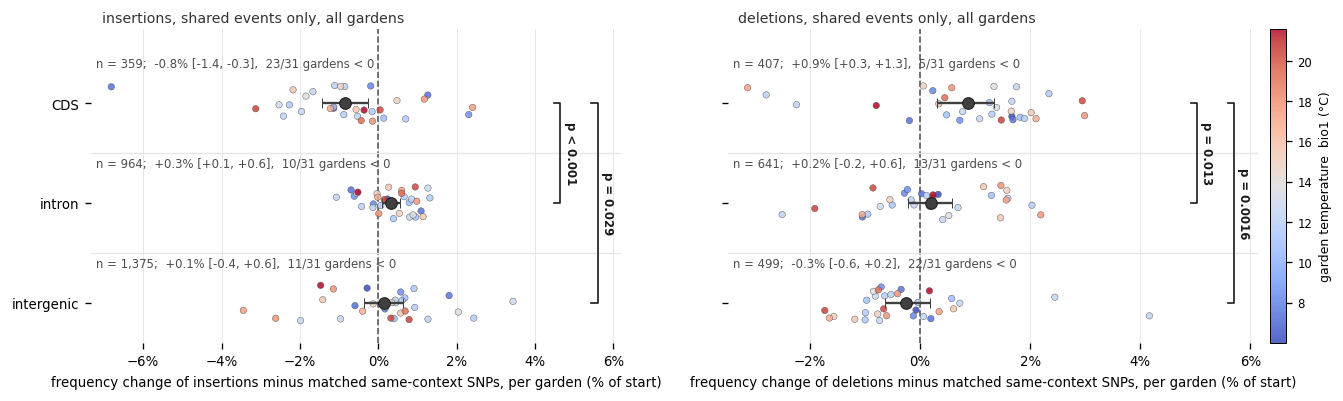

      kind    context  n_events    mean  boot_lo  boot_hi  ci_excludes_0  gardens_below  matched_snp_null_p
insertions        CDS       359 -0.0084  -0.0145  -0.0027           True             23               0.241
insertions     intron       964  0.0033   0.0010   0.0055           True             10               0.350
insertions intergenic      1375  0.0015  -0.0036   0.0064          False             11               0.711
 deletions        CDS       407  0.0087   0.0031   0.0134           True              5               0.048
 deletions     intron       641  0.0020  -0.0021   0.0059          False             13               0.589
 deletions intergenic       499 -0.0026  -0.0064   0.0017          False             22               0.466

coding sequence against the two non-coding contexts, within each SV type (difference of the matched differences):
      kind         contrast  mean_diff  boot_lo  boot_hi  gardens_below  wilcoxon_p  significant  matched_snp_null_p
insertions  

      kind    context  n (all)           mean (all) gardens<0 (all)  event_boot_p (all)
insertions        CDS      715 -0.69% [-1.25,-0.18]           21/31               0.475
insertions     intron     1532 +0.22% [+0.01,+0.45]           11/31               0.595
insertions intergenic     2402 +0.05% [-0.49,+0.58]           14/31               0.925
 deletions        CDS      692 +0.71% [+0.11,+1.20]            7/31               0.170
 deletions     intron      919 +0.16% [-0.22,+0.53]           14/31               0.820
 deletions intergenic      818 -0.27% [-0.70,+0.20]           21/31               0.630

      kind    context  n (shared)        mean (shared) gardens<0 (shared)  event_boot_p (shared)
insertions        CDS         359 -0.84% [-1.45,-0.27]              23/31                  0.305
insertions     intron         964 +0.33% [+0.10,+0.55]              10/31                  0.465
insertions intergenic        1375 +0.15% [-0.36,+0.64]              11/31                  0

In [ ]:

SHARED=(ORG=="shared")
T_sh,_=lead_figure(stat_freq,SHARED,"shared events only, all gardens",XF,True,
                   "main_fig2_lead_frequency_shared.png",tag="1a frequency, shared")
show(T_sh)

def _ld(idx,si,w):
    Ls=np.nansum(PV[idx],0); Ln=np.nansum(PV[si]*w[:,None],0); return (Ls[1:]/Ls[0]-1)-(Ln[1:]/Ln[0]-1)
_rg3=np.random.default_rng(0)
print("\nshared events vs all events, same statistic, with the event-level bootstrap added:")
rows=[]
for k in ("ins","del"):
    for ctx in SUMC:
        ci=CTX.index(ctx); r=dict(kind=KL[k],context=ctx)
        for slab,flt in (("all",np.ones(KD.size,bool)),("shared",SHARED)):
            ms=(KD==k)&(CX==ci)&flt; mn=(KD=="snp")&(CX==ci)&flt
            si,w,_=matched_snps(ms,mn); im=np.where(ms)[0]; d=_ld(im,si,w); lo,hi=bci(d)
            bs=np.array([_ld(_rg3.choice(im,im.size),si,w).mean() for _ in range(400)])
            r[f"n ({slab})"]=int(ms.sum())
            r[f"mean ({slab})"]=f"{100*d.mean():+.2f}% [{100*lo:+.2f},{100*hi:+.2f}]"
            r[f"gardens<0 ({slab})"]=f"{int((d<0).sum())}/31"
            r[f"event_boot_p ({slab})"]=round(2*min((bs>=0).mean(),(bs<=0).mean()),3)
        rows.append(r)
TS=pd.DataFrame(rows)
print(TS[["kind","context","n (all)","mean (all)","gardens<0 (all)","event_boot_p (all)"]].to_string(index=False))
print()
print(TS[["kind","context","n (shared)","mean (shared)","gardens<0 (shared)","event_boot_p (shared)"]].to_string(index=False))


### The same comparison with the event as the unit — per-event percentile against its own matched SNPs

The lead figure asks one question per garden: it collapses a whole class into a single summed-frequency
change, so the analysis has 31 units and all per-event information is discarded. This is the same
comparison re-cast so that **the unit is the SV event**.

**Statistic.** For each event *v*, its mean relative frequency change over the 31 gardens,
mean<sub>*s*</sub>[(*p*<sub>*v,s*</sub> − *p*<sub>0,*v*</sub>) / *p*<sub>0,*v*</sub>]. Each event is then
given its **percentile *u* among the SNPs of its own exact matching cell** — same genomic context, same
number of carrier founders, same carrier-origin-climate quintile (cells with fewer than 5 SNPs fall back
to the carrier-count-bin cell, as elsewhere). Ties are split evenly.

*u* < 0.5 means the event fell further than the median matched SNP. Under the null that events behave
like same-cell SNPs, *u* ~ Uniform(0, 1), so the class mean is 0.5 and its standard error is
1/√(12*n*) — the dashed line and the error bars below are on that scale.

**Tests.** Point and interval: mean *u* with a 95% percentile bootstrap over **events** (2,000
resamples). Brackets: two-sided **Mann-Whitney U** on the *u* distributions of CDS against intron
(inner) and CDS against intergenic (outer) — because *u* is already each event's rank against its own
matched SNPs, comparing two contexts' *u* distributions is a clean two-sample test with the event as
the unit. Line weight marks p < 0.05; no correction for the number of contrasts.

**Calibration.** Treating a random half of a context's SNPs as if it were the class and ranking it
against the other half gives mean *u* = 0.4996–0.5034 over six random splits (sd 0.0013–0.0042), i.e. a
small positive bias of about +0.002. That bias makes a negative (insertion-like) shift slightly
conservative and a positive (deletion-like) shift slightly inflated.

**Power, stated up front.** Because *u* has SD = 1/√12 = 0.289 by construction, the smallest shift
resolvable at p < 0.05 is 0.030 at *n* = 359 and 0.021 at *n* = 715. The shifts measured here are of
the same magnitude, so this panel should be read as an effect size with its detection limit, not as a
significance test.

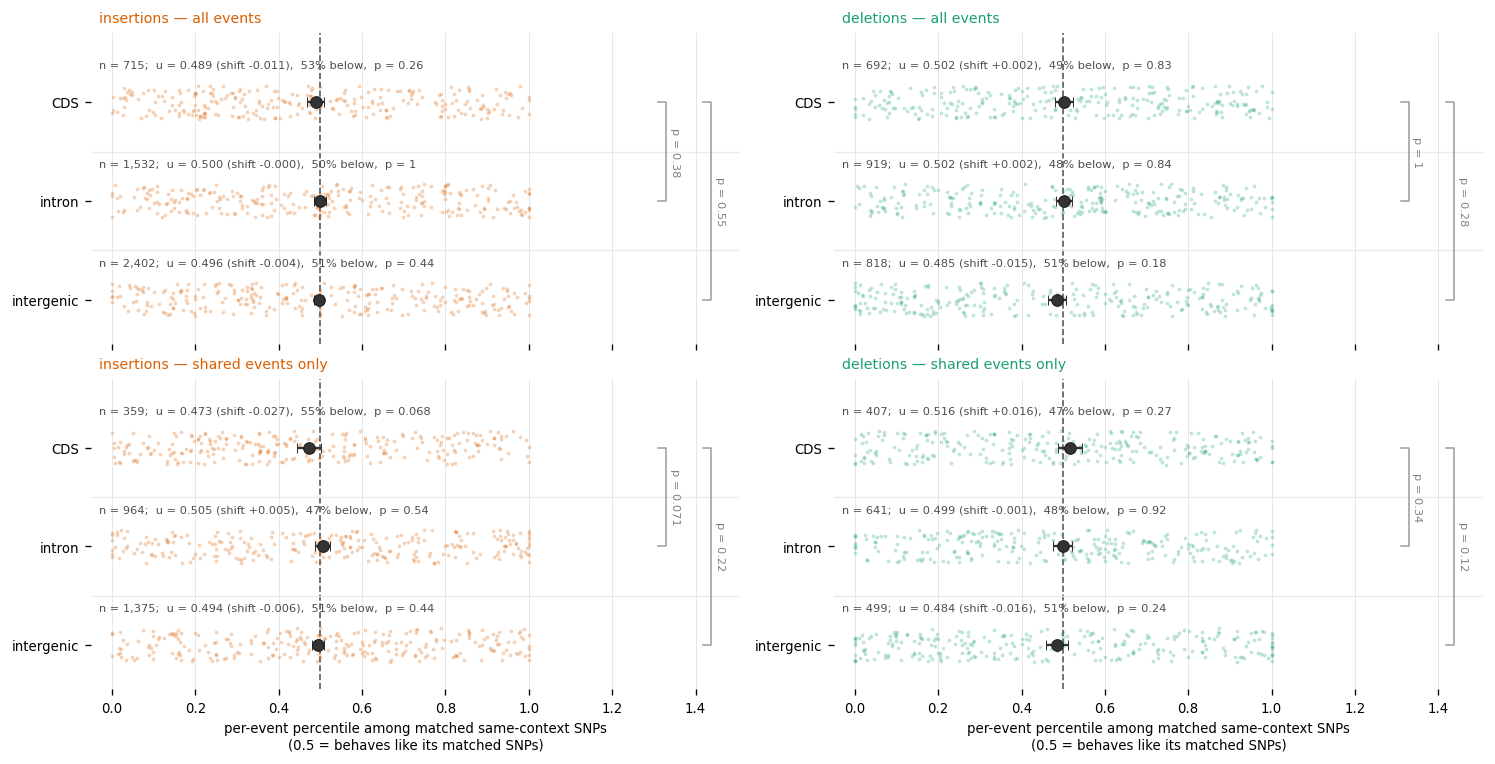


all events
      kind    context  n_events  mean_u   shift  boot_lo  boot_hi  frac_below  se_null  p_eventboot
insertions        CDS       715  0.4886 -0.0114   0.4681   0.5092      0.5315   0.0108        0.263
insertions     intron      1532  0.4999 -0.0001   0.4851   0.5144      0.4954   0.0074        0.997
insertions intergenic      2402  0.4955 -0.0045   0.4842   0.5070      0.5083   0.0059        0.439
 deletions        CDS       692  0.5022  0.0022   0.4806   0.5237      0.4899   0.0110        0.828
 deletions     intron       919  0.5021  0.0021   0.4835   0.5205      0.4842   0.0095        0.837
 deletions intergenic       818  0.4855 -0.0145   0.4644   0.5062      0.5098   0.0101        0.179

shared events only
      kind    context  n_events  mean_u   shift  boot_lo  boot_hi  frac_below  se_null  p_eventboot
insertions        CDS       359  0.4731 -0.0269   0.4434   0.5021      0.5515   0.0152        0.068
insertions     intron       964  0.5053  0.0053   0.4873   0.5239   

In [ ]:

from scipy.stats import mannwhitneyu
with np.errstate(invalid="ignore",divide="ignore"):
    UREL=np.nanmean((PV[:,1:]-PV[:,:1])/PV[:,:1],axis=1)          # per-event mean relative frequency change
def pctl(ev,snp,x):
    # each event's percentile among the SNPs of its own exact cell (fallback: its carrier-count-bin cell)
    out=np.full(ev.size,np.nan)
    for cellv in (CELLX,CELLB):
        byc={}
        for c in np.unique(cellv[snp]):
            v=x[snp][cellv[snp]==c]; v=v[~np.isnan(v)]
            if v.size>=5: byc[c]=np.sort(v)
        for i,e in enumerate(ev):
            if not np.isnan(out[i]) or np.isnan(x[e]): continue
            v=byc.get(cellv[e])
            if v is None: continue
            out[i]=(np.searchsorted(v,x[e],"left")+np.searchsorted(v,x[e],"right"))/2.0/v.size
    return out[~np.isnan(out)]
_rgu=np.random.default_rng(0)
SETSU=(("all events",np.ones(KD.size,bool)),("shared events only",ORG=="shared"))
UU={}; URWS=[]
for slab,om in SETSU:
    for kind in ("ins","del"):
        for ctx in SUMC:
            ci=CTX.index(ctx)
            u=pctl(np.where(om&(KD==kind)&(CX==ci))[0],np.where(om&(KD=="snp")&(CX==ci))[0],UREL)
            UU[(slab,kind,ctx)]=u
            bs=_rgu.choice(u,(2000,u.size)).mean(1); lo,hi=np.percentile(bs,[2.5,97.5])
            URWS.append(dict(event_set=slab,kind=KL[kind],context=ctx,n_events=u.size,mean_u=u.mean(),
                             shift=u.mean()-0.5,boot_lo=lo,boot_hi=hi,frac_below=(u<0.5).mean(),
                             se_null=np.sqrt(1/12/u.size),
                             p_eventboot=2*min((bs>=0.5).mean(),(bs<=0.5).mean())))
fig,ax=plt.subplots(2,2,figsize=(12.5,6.4),sharex="col")
for ri,(slab,om) in enumerate(SETSU):
    for cj,kind in enumerate(("ins","del")):
        a=ax[ri,cj]; style(a,axis="x"); a.axvline(0.5,color="0.35",lw=1,ls="--")
        for yi,ctx in enumerate(SUMC):
            u=UU[(slab,kind,ctx)]
            sub=u if u.size<=260 else _rgu.choice(u,260,replace=False)
            a.scatter(sub,yi+_rgu.uniform(-0.17,0.17,sub.size),s=5,color=KC[kind],alpha=0.28,linewidth=0,zorder=2)
            r=[q for q in URWS if (q["event_set"],q["kind"],q["context"])==(slab,KL[kind],ctx)][0]
            a.errorbar(r["mean_u"],yi,xerr=[[r["mean_u"]-r["boot_lo"]],[r["boot_hi"]-r["mean_u"]]],fmt="o",ms=7,
                       color="0.2",mec="0.1",mew=0.6,capsize=3,elinewidth=1.4,zorder=4)
            a.annotate(f"n = {r['n_events']:,};  u = {r['mean_u']:.3f} (shift {r['shift']:+.3f}),  "
                       f"{100*r['frac_below']:.0f}% below,  p = {r['p_eventboot']:.2g}",
                       xy=(0.012,yi-0.42),xycoords=("axes fraction","data"),ha="left",va="top",fontsize=6.8,color="0.3")
            if yi<2: a.axhline(yi+0.5,color="0.92",lw=0.8)
        x0,x1=a.get_xlim(); a.set_xlim(x0,x1+0.19*(x1-x0)); tr=a.get_yaxis_transform()
        for yi,(ctx,xb) in enumerate(zip(SUMC[1:],(0.885,0.955)),1):
            p_=mannwhitneyu(UU[(slab,kind,"CDS")],UU[(slab,kind,ctx)],alternative="two-sided").pvalue
            sig=p_<0.05
            a.plot([xb-0.012,xb,xb,xb-0.012],[0,0,yi,yi],transform=tr,color="0.1" if sig else "0.6",
                   lw=1.6 if sig else 0.9,clip_on=False,zorder=5)
            a.text(xb+0.006,yi/2,f"p = {p_:.2g}",transform=tr,rotation=270,ha="left",va="center",
                   fontsize=6.8,color="0.1" if sig else "0.5")
        a.set_yticks(range(3)); a.set_yticklabels(SUMC,fontsize=8); a.set_ylim(2.45,-0.7)
        a.annotate(f"{KL[kind]} — {slab}",xy=(0.012,1.035),xycoords="axes fraction",fontsize=8.5,color=KC[kind])
        if ri==1: a.set_xlabel("per-event percentile among matched same-context SNPs\n(0.5 = behaves like its matched SNPs)",fontsize=8)
fig.tight_layout()
fig.savefig(f"{G}/plots/main_fig2_perevent_percentile.png",dpi=200,bbox_inches="tight"); plt.show()
TU=pd.DataFrame(URWS)
for s,_ in SETSU:
    print(f"\n{s}"); print(TU[TU.event_set==s].drop(columns="event_set").round(4).to_string(index=False))
print("\nper-event CDS vs non-coding contrast (Mann-Whitney U on the u distributions):")
for s,_ in SETSU:
    for kind in ("ins","del"):
        for other in ("intron","intergenic"):
            a_,b_=UU[(s,kind,"CDS")],UU[(s,kind,other)]
            print(f"  {s:<19}{KL[kind]:<11}CDS vs {other:<11} delta u = {a_.mean()-b_.mean():+.4f}   "
                  f"p = {mannwhitneyu(a_,b_,alternative='two-sided').pvalue:.4f}")


### The same comparison with the event as the unit, in units of frequency change

The lead figure asks one question per garden: it sums a whole class into a single frequency change, so
the analysis has 31 units and every per-event difference is averaged away. This is the same comparison
with **the event as the unit**, in the same units as 1a — percent of starting frequency.

**Statistic.** For each event *v*: its mean relative frequency change over the 31 gardens,
mean<sub>*s*</sub>[(*p*<sub>*v,s*</sub> − *p*<sub>0,*v*</sub>) / *p*<sub>0,*v*</sub>], **minus the median
of that same quantity over the SNPs of its own matching cell** — same genomic context, same number of
carrier founders, same carrier-origin-climate quintile (cells with fewer than 5 SNPs fall back to the
carrier-count-bin cell, as elsewhere). One number per event, in percent of the event's own starting
frequency. **0 means the event moved like the SNPs matched to it**; negative means it fell further.

**Why the median and not the mean, on both sides.** Relative change is a ratio with *p*<sub>0</sub> in
the denominator, so a rare event that happens to rise is unbounded above (a variant at *p*<sub>0</sub> =
0.005 reaching 0.05 is +900%) while the worst case is −100%. The distribution is therefore strongly
right-skewed and its mean is not a useful summary — for all CDS insertions the mean is +6.1% while the
median is −2.2%. The median is used for the class summary and for the per-cell SNP reference; the mean
is printed in the table only to show the skew.

**Tests.** Point and interval: the class median with a 95% percentile bootstrap CI over **events**
(2,000 resamples); *p* is the two-sided share of those resamples falling on the other side of 0. The
final column gives the fraction of the class's events below 0, whose null value is 50%.

Open markers are all events, filled markers shared events only (carried by at least one cold-origin and
one warm-origin founder, against shared SNPs matched the same way).

**Brackets.** Two-sided Mann-Whitney U on the per-event distributions, CDS against intron (inner) and
CDS against intergenic (outer), on the shared set; heavier line marks p < 0.05. No correction for the
number of contrasts.

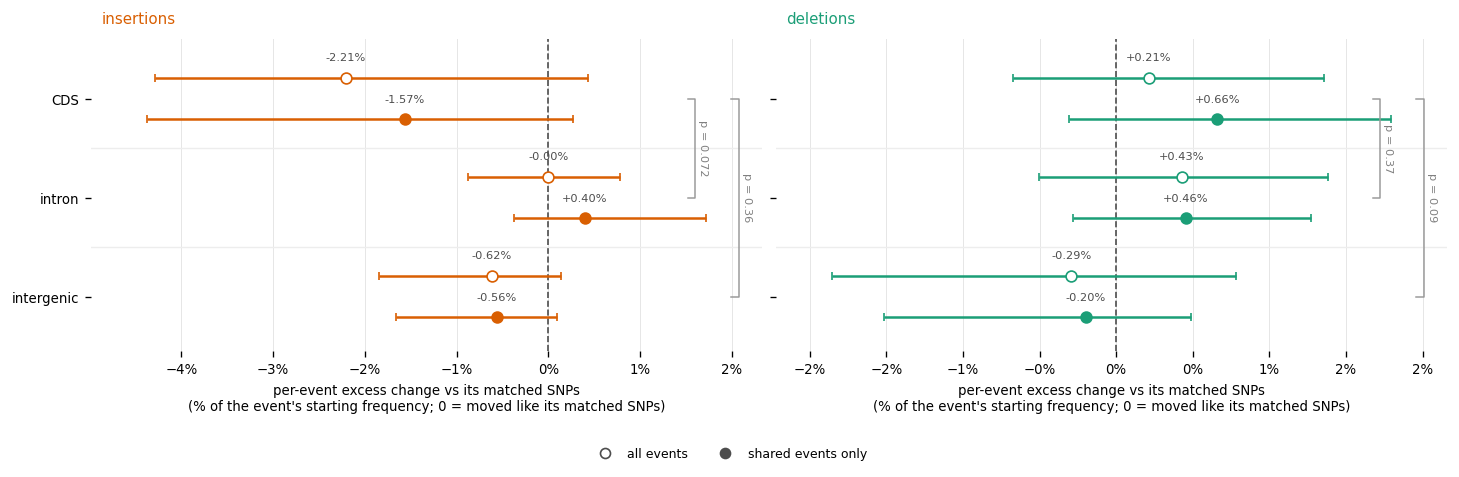

median_pct: class median of the per-event excess change, % of starting frequency (0 = null)
mean_pct_skewed: the mean of the same values -- shown only to document the right skew (see markdown)

all events
      kind    context  n_events  median_pct  boot_lo  boot_hi  p_eventboot  mean_pct_skewed  frac_below_0
insertions        CDS       715       -2.21    -4.29     0.43         0.08             6.11         53.15
insertions     intron      1532       -0.00    -0.88     0.79         0.98             6.44         50.00
insertions intergenic      2402       -0.62    -1.84     0.14         0.17             5.44         51.42
 deletions        CDS       692        0.21    -0.67     1.35         0.70             6.29         49.28
 deletions     intron       919        0.43    -0.50     1.38         0.37             4.14         48.53
 deletions intergenic       818       -0.29    -1.85     0.78         0.51             5.54         51.22

shared events
      kind    context  n_events  media

In [ ]:

from scipy.stats import mannwhitneyu
with np.errstate(invalid="ignore",divide="ignore"):
    REL8=np.nanmean((PV[:,1:]-PV[:,:1])/PV[:,:1],axis=1)      # per-event mean relative frequency change
def excess(ev,snp,x):
    # event's value minus the median value of the SNPs in its own matching cell
    out=np.full(ev.size,np.nan)
    for cellv in (CELLX,CELLB):
        med={}
        for c in np.unique(cellv[snp]):
            v=x[snp][cellv[snp]==c]; v=v[~np.isnan(v)]
            if v.size>=5: med[c]=np.median(v)
        for i,e in enumerate(ev):
            if not np.isnan(out[i]) or np.isnan(x[e]): continue
            m=med.get(cellv[e])
            if m is not None: out[i]=x[e]-m
    return out[~np.isnan(out)]
_rg8=np.random.default_rng(0); SETS8=(("all",-0.21,"white"),("shared",0.21,None))
E8={}; R8=[]
for slab,_o,_f in SETS8:
    om=np.ones(KD.size,bool) if slab=="all" else (ORG=="shared")
    for kind in ("ins","del"):
        for ctx in SUMC:
            ci=CTX.index(ctx)
            d=excess(np.where(om&(KD==kind)&(CX==ci))[0],np.where(om&(KD=="snp")&(CX==ci))[0],REL8)
            E8[(slab,kind,ctx)]=d
            bs=np.median(_rg8.choice(d,(2000,d.size)),axis=1); lo,hi=np.percentile(bs,[2.5,97.5])
            R8.append(dict(event_set=slab,kind=KL[kind],context=ctx,n_events=d.size,
                           median_pct=100*np.median(d),boot_lo=100*lo,boot_hi=100*hi,
                           p_eventboot=2*min((bs>=0).mean(),(bs<=0).mean()),
                           mean_pct_skewed=100*d.mean(),frac_below_0=100*(d<0).mean()))
T8=pd.DataFrame(R8)
fig,ax=plt.subplots(1,2,figsize=(12.2,3.6),sharey=True)
for a,kind in zip(ax,("ins","del")):
    style(a,axis="x"); a.axvline(0,color="0.3",lw=1,ls="--",zorder=2)
    for yi,ctx in enumerate(SUMC):
        for slab,off,fc in (("all",-0.21,"white"),("shared",0.21,KC[kind])):
            r=[q for q in R8 if (q["event_set"],q["kind"],q["context"])==(slab,KL[kind],ctx)][0]
            a.errorbar(r["median_pct"],yi+off,xerr=[[r["median_pct"]-r["boot_lo"]],[r["boot_hi"]-r["median_pct"]]],
                       fmt="o",ms=6.5,mfc=fc,color=KC[kind],ecolor=KC[kind],elinewidth=1.5,capsize=2.5,zorder=4)
            a.annotate(f"{r['median_pct']:+.2f}%",xy=(r["median_pct"],yi+off-0.15),ha="center",va="bottom",
                       fontsize=6.8,color="0.3")
        if yi<2: a.axhline(yi+0.5,color="0.93",lw=0.8)
    _lo=min(q["boot_lo"] for q in R8 if q["kind"]==KL[kind]); _hi=max(q["boot_hi"] for q in R8 if q["kind"]==KL[kind])
    _pad=0.10*(_hi-_lo); a.set_xlim(_lo-_pad,_hi+_pad); tr=a.get_yaxis_transform()
    for yi,(ctx,xb) in enumerate(zip(SUMC[1:],(0.90,0.965)),1):
        p_=mannwhitneyu(E8[("shared",kind,"CDS")],E8[("shared",kind,ctx)],alternative="two-sided").pvalue
        sig=p_<0.05
        a.plot([xb-0.011,xb,xb,xb-0.011],[0,0,yi,yi],transform=tr,color="0.1" if sig else "0.6",
               lw=1.7 if sig else 0.9,clip_on=False,zorder=5)
        a.text(xb+0.005,yi/2,f"p = {p_:.2g}",transform=tr,rotation=270,ha="left",va="center",
               fontsize=6.8,color="0.1" if sig else "0.5")
    a.set_yticks(range(3)); a.set_yticklabels(SUMC,fontsize=8); a.set_ylim(2.55,-0.6)
    a.xaxis.set_major_formatter(PercentFormatter(100,decimals=0))
    a.set_xlabel("per-event excess change vs its matched SNPs\n(% of the event's starting frequency; 0 = moved like its matched SNPs)",fontsize=8)
    a.annotate(KL[kind],xy=(0.015,1.05),xycoords="axes fraction",fontsize=9,color=KC[kind])
fig.legend(handles=[Line2D([0],[0],marker="o",ls="none",mfc="white",color="0.3",label="all events"),
                    Line2D([0],[0],marker="o",ls="none",color="0.3",label="shared events only")],
           frameon=False,fontsize=7.5,loc="lower center",ncol=2,bbox_to_anchor=(0.5,-0.10))
fig.tight_layout()
fig.savefig(f"{G}/plots/main_fig2_perevent_excess_change.png",dpi=200,bbox_inches="tight"); plt.show()
print("median_pct: class median of the per-event excess change, % of starting frequency (0 = null)")
print("mean_pct_skewed: the mean of the same values -- shown only to document the right skew (see markdown)\n")
for s in ("all","shared"):
    print(f"{s} events"); print(T8[T8.event_set==s].drop(columns="event_set").round(2).to_string(index=False)); print()
